<a href="https://colab.research.google.com/github/CA683-Group99/Wind-Energy-Prediction/blob/main/eirgrid_download_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### pre-reqs

In [35]:
!pip install pandas requests
!pip install tenacity

import pandas as pd
import requests
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Simple test functions to undertnad the data

In [ ]:
from tenacity import retry, wait_exponential, stop_after_attempt, retry_if_exception_type
import urllib.parse

@retry(wait=wait_exponential(multiplier=1, min=4, max=10),
        stop=stop_after_attempt(5),
        retry=retry_if_exception_type(requests.exceptions.HTTPError))
def fetch_dashboard_metric_with_retry(area: str, region: str = "ROI", duration_days: int = 7, to_days: int = 0) -> pd.DataFrame:
    """Fetch grid metrics from EirGrid's DashboardService endpoint with retry logic."""
    end = datetime.now() - timedelta(hours=3) - timedelta(days=to_days) # Fetch up to current time minus 3 hours
    start = end - timedelta(days=duration_days)

    datefrom = start.strftime("%d-%b-%Y %H:00")
    dateto = end.strftime("%d-%b-%Y %H:59")

    # Explicitly quote date parameters to handle spaces and other special characters
    quoted_datefrom = urllib.parse.quote(datefrom)
    quoted_dateto = urllib.parse.quote(dateto)

    url = f"https://www.smartgriddashboard.com/DashboardService.svc/data?area={area}&region={region}&datefrom={quoted_datefrom}&dateto={quoted_dateto}"

    print(f"Calling URL: {url}") # Log the URL
    response = requests.get(url, timeout=15)
    response.raise_for_status()
    data = response.json()

    if "Rows" in data and data["Rows"]:
        df = pd.DataFrame(data["Rows"])
        df['EffectiveTime'] = pd.to_datetime(df['EffectiveTime'])
        df_pivot = df.pivot_table(index='EffectiveTime', columns='FieldName', values='Value')
        print(f"DataFrame for {area} has {len(df_pivot)} rows.") # Log the number of rows
        return df_pivot

    print(f"DataFrame for {area} is empty.") # Log if DataFrame is empty
    return pd.DataFrame()

@retry(wait=wait_exponential(multiplier=1, min=4, max=10),
        stop=stop_after_attempt(5),
        retry=retry_if_exception_type(requests.exceptions.HTTPError))
def fetch_vargen_solar_with_retry(region: str = "ROI", duration_days: int = 7, to_days: int = 0 ) -> pd.DataFrame:
    """Fetch 15-minute actual solar generation from EirGrid's VarGen API with retry logic."""
    end = datetime.now() - timedelta(hours=3) - timedelta(days=to_days)  # Fetch up to current time
    start = end - timedelta(days=duration_days)

    #datefrom = start.strftime("%d-%b-%Y %H:00")
    #dateto = end.strftime("%d-%b-%Y %H:59")
    start_str = start.strftime("%Y%m%d%H00")  # was %M
    end_str = end.strftime("%Y%m%d%H59")

    url = f"https://www.vargen.smartgriddashboard.com/api/export/{start_str}/{end_str}/{region}/SOLAR?FORMAT=JSON"

    print(f"Calling URL: {url}") # Log the URL
    response = requests.get(url, timeout=15)
    response.raise_for_status()
    data = response.json()

    if "Rows" in data and data["Rows"]:
        df = pd.DataFrame(data["Rows"])
        if "FieldName" in df.columns:
            df = df[df["FieldName"] == "SOLAR_ACTUAL"]

        df["Timestamp"] = pd.to_datetime(df["Effective_Date"], format="%d-%m-%Y %H:%M:%S")
        df = df[["Timestamp", "MW_ACTUAL", "MW_FORECAST"]].rename(columns={"MW_ACTUAL": "solar_actual"})
        df["solar_actual"] = pd.to_numeric(df["solar_actual"], errors="coerce")

        df = df.rename(columns={"MW_FORECAST": "solar_forecast"})
        df["solar_forecast"] = pd.to_numeric(df["solar_forecast"], errors="coerce")
        print(f"DataFrame for solar_actual has {len(df)} rows.") # Log the number of rows
        return df.drop_duplicates(subset=["Timestamp"]).set_index("Timestamp")

    print(f"DataFrame for solaractual is empty.") # Log if DataFrame is empty
    return pd.DataFrame()

In [ ]:
solardf = fetch_vargen_solar_with_retry(region="ROI", duration_days=10, to_days=400)
display(solardf.tail())

Calling URL: https://www.vargen.smartgriddashboard.com/api/export/202507101000/202507201059/ROI/SOLAR?FORMAT=JSON
DataFrame for solar_actual has 964 rows.


,solar_actual,solar_forecast
Timestamp,,
2025-07-20 09:45:00,323,86
2025-07-20 10:00:00,386,97
2025-07-20 10:15:00,355,112
2025-07-20 10:30:00,465,127
2025-07-20 10:45:00,425,142


In [ ]:
end = datetime.now() - timedelta(days=300)
start = end - timedelta(days=3)

start_str = start.strftime("%Y%m%d0000")
end_str = end.strftime("%Y%m%d2359")

url = f"https://www.vargen.smartgriddashboard.com/api/export/{start_str}/{end_str}/ROI/WIND?FORMAT=JSON"

print(f"Calling URL: {url}") # Log the URL
response = requests.get(url, timeout=15)
response.raise_for_status()
data = response.json()

if "Rows" in data and data["Rows"]:
    df = pd.DataFrame(data["Rows"])
    if "FieldName" in df.columns:
        df = df[df["FieldName"] == "wnd_ACTUAL"]
    display(df.head())

Calling URL: https://www.vargen.smartgriddashboard.com/api/export/202510250000/202510282359/ROI/WIND?FORMAT=JSON


,Effective_Date,MW_ACTUAL,MW_FORECAST,Region
0,25-10-2025 00:00:00,2011,3068,ROI
1,25-10-2025 00:15:00,2117,3063,ROI
2,25-10-2025 00:30:00,2168,3058,ROI
3,25-10-2025 00:45:00,2126,3054,ROI
4,25-10-2025 01:00:00,2105,3178,ROI


In [ ]:
if "Rows" in data and data["Rows"]:
  df = pd.DataFrame(data["Rows"])
  display(df.tail())

  df["Timestamp"] = pd.to_datetime(df["Effective_Date"], format="%d-%m-%Y %H:%M:%S")
  df = df[["Timestamp", "MW_ACTUAL", "MW_FORECAST"]].rename(columns={"MW_ACTUAL": "solar_actual"})
  df["solar_actual"] = pd.to_numeric(df["solar_actual"], errors="coerce")

  df = df.rename(columns={"MW_FORECAST": "solar_forecast"})
  df["solar_forecast"] = pd.to_numeric(df["solar_forecast"], errors="coerce")
  print(f"DataFrame for solar_actual has {len(df)} rows.") # Log the number of rows
  df = df.drop_duplicates(subset=["Timestamp"]).set_index("Timestamp")

  # Define the path where you want to save the CSV file in your Google Drive
  output_path = '/content/drive/My Drive/climate/energy2026/eirgrid_solar.csv'

  # Save the DataFrame to CSV
  df.to_csv(output_path, index=True) # Set index=False if you don't want to write the DataFrame index

  print(f"DataFrame saved successfully to {output_path}")
  display(df.tail())


,Effective_Date,MW_ACTUAL,MW_FORECAST,Region
379,21-08-2026 22:45:00,,869,ROI
380,21-08-2026 23:00:00,,847,ROI
381,21-08-2026 23:15:00,,824,ROI
382,21-08-2026 23:30:00,,801,ROI
383,21-08-2026 23:45:00,,779,ROI


DataFrame for solar_actual has 384 rows.
DataFrame saved successfully to /content/drive/My Drive/climate/energy2026/eirgrid_solar.csv


,solar_actual,solar_forecast
Timestamp,,
2026-08-21 22:45:00,NaN,869
2026-08-21 23:00:00,NaN,847
2026-08-21 23:15:00,NaN,824
2026-08-21 23:30:00,NaN,801
2026-08-21 23:45:00,NaN,779


In [ ]:
new_df = pd.read_csv(output_path, index_col=0, parse_dates=True)
display(new_df.head())

,solar_actual,solar_forecast
Timestamp,,
2026-08-18 00:00:00,1726.0,1559
2026-08-18 00:15:00,1678.0,1539
2026-08-18 00:30:00,1726.0,1520
2026-08-18 00:45:00,1718.0,1500
2026-08-18 01:00:00,1690.0,1529


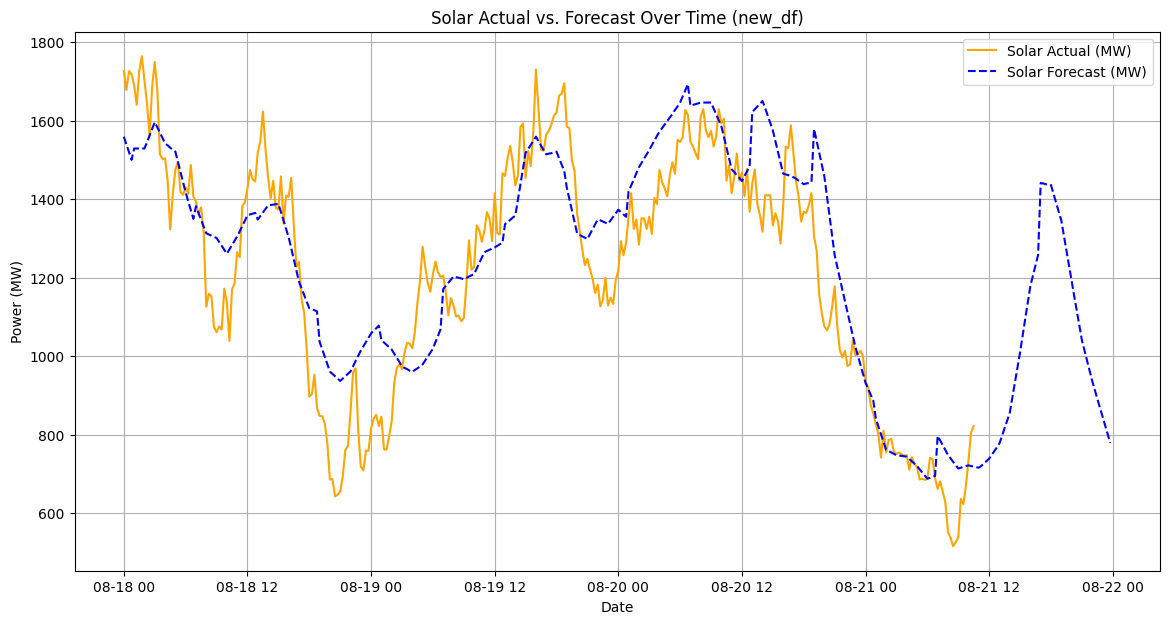

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))
plt.plot(new_df.index, new_df['solar_actual'], label='Solar Actual (MW)', color='orange')
plt.plot(new_df.index, new_df['solar_forecast'], label='Solar Forecast (MW)', color='blue', linestyle='--')

plt.title('Solar Actual vs. Forecast Over Time (new_df)')
plt.xlabel('Date')
plt.ylabel('Power (MW)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
metrics = ["co2intensity"]
#metrics = ["demandactual", "windactual", "interconnection", "co2intensity"]

frames = []

for area in metrics:
    # Using the retry-enabled function
    df = fetch_dashboard_metric_with_retry(area, region="ALL", duration_days=3)
    if not df.empty:
        frames.append(df)

# Define the path where you want to save the CSV file in your Google Drive
output_path = '/content/drive/My Drive/climate/energy2026/eirgrid_co2intensity.csv'

# Save the DataFrame to CSV
df.to_csv(output_path, index=True) # Set index=False if you don't want to write the DataFrame index

print(f"DataFrame saved successfully to {output_path}")

display(df.head())

Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=co2intensity&region=ALL&datefrom=18-Aug-2026%2011%3A00&dateto=21-Aug-2026%2011%3A59
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=co2intensity&region=ALL&datefrom=18-Aug-2026%2011%3A00&dateto=21-Aug-2026%2011%3A59
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=co2intensity&region=ALL&datefrom=18-Aug-2026%2011%3A00&dateto=21-Aug-2026%2011%3A59
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=co2intensity&region=ALL&datefrom=18-Aug-2026%2011%3A00&dateto=21-Aug-2026%2011%3A59
DataFrame for co2intensity has 292 rows.
DataFrame saved successfully to /content/drive/My Drive/climate/energy2026/eirgrid_co2intensity.csv


FieldName,CO2_INTENSITY
EffectiveTime,
2026-08-18 11:00:00,148.0
2026-08-18 11:15:00,152.0
2026-08-18 11:30:00,160.0
2026-08-18 11:45:00,164.0
2026-08-18 12:00:00,149.0


In [ ]:
print("\nCounts per 'FieldName' and 'Region' combination:")
display(df.groupby(['FieldName', 'Region']).size())


Counts per 'FieldName' and 'Region' combination:


,,0
FieldName,Region,
INTER_EWIC,ROI,384
INTER_GRNLK,ROI,384
INTER_MOYLE,NI,384
INTER_NET,ALL,384


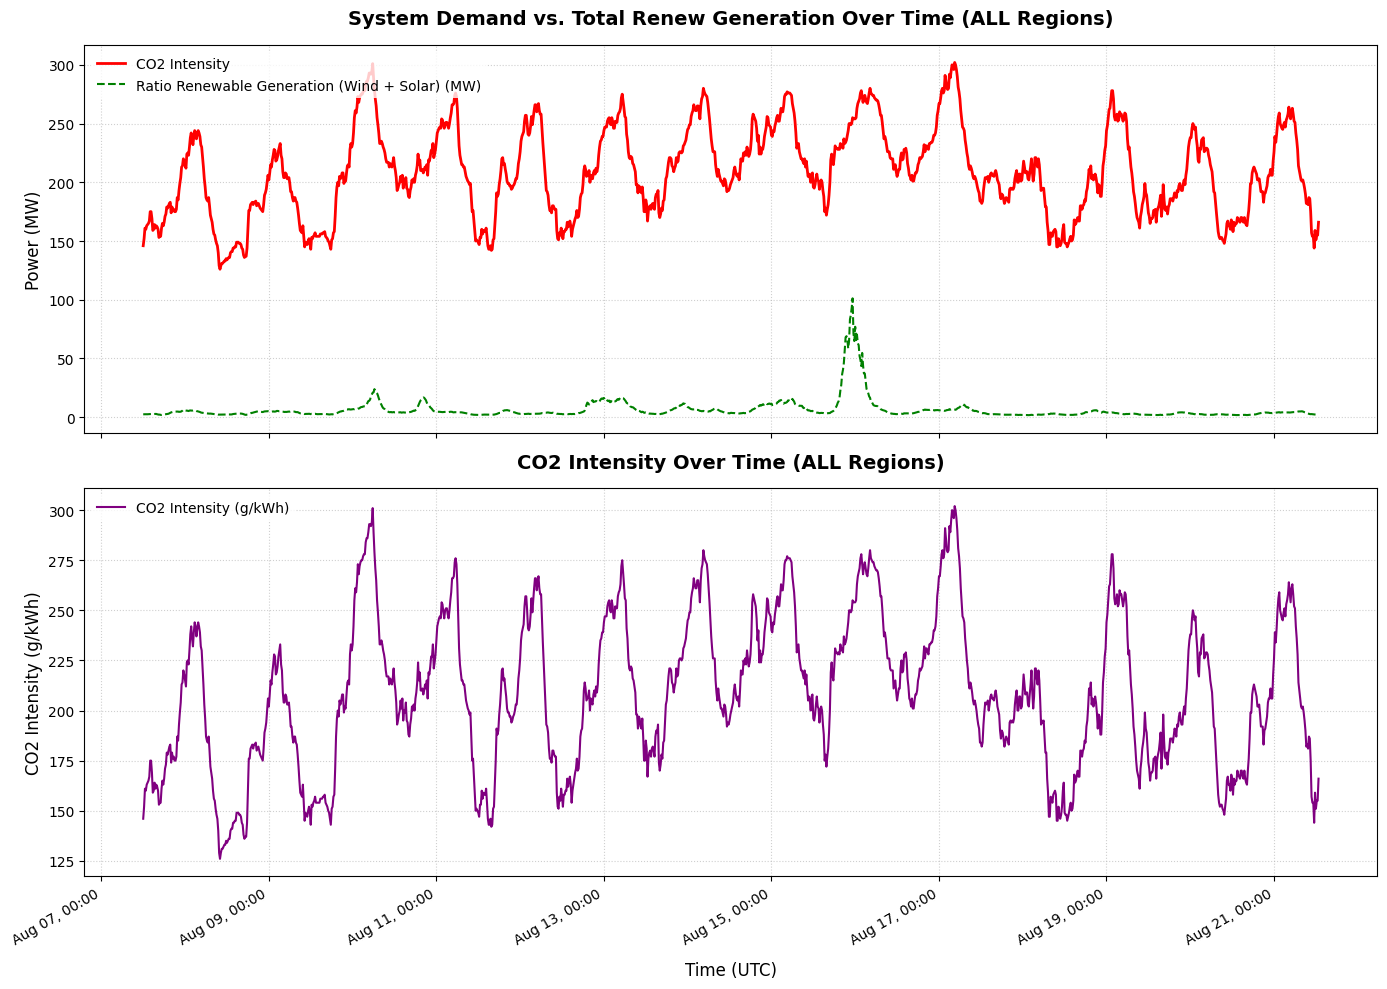

In [ ]:
# Ensure 'TOTAL_GENERATION' is calculated in eirgrid_df
# This calculation was previously in a separate plotting cell, so we'll ensure it's here
eirgrid_df['TOTAL_REN_GENERATION'] = eirgrid_df['WIND_ACTUAL'] + eirgrid_df['solar_actual']
eirgrid_df['RATIO_REN_GENERATION'] = eirgrid_df['SYSTEM_DEMAND'] / eirgrid_df['TOTAL_REN_GENERATION']


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True) # Share x-axis for alignment

# --- Plot 1: System Demand vs. Total Generation ---
ax1.plot(eirgrid_df.index, eirgrid_df['CO2_INTENSITY'], label='CO2 Intensity', color='red', linewidth=2.0)
ax1.plot(eirgrid_df.index, eirgrid_df['RATIO_REN_GENERATION'], label='Ratio Renewable Generation (Wind + Solar) (MW)', color='green', linewidth=1.5, linestyle='--')

ax1.set_title('System Demand vs. Total Renew Generation Over Time (ALL Regions)', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('Power (MW)', fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')

# --- Plot 2: CO2 Intensity ---
ax2.plot(eirgrid_df.index, eirgrid_df['CO2_INTENSITY'], label='CO2 Intensity (g/kWh)', color='purple', linewidth=1.5)

ax2.set_title('CO2 Intensity Over Time (ALL Regions)', fontsize=14, fontweight='bold', pad=15)
ax2.set_xlabel('Time (UTC)', fontsize=12, labelpad=10)
ax2.set_ylabel('CO2 Intensity (g/kWh)', fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')

# Date formatting on X-axis (applied to both since sharex=True)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %d, %H:%M"))
plt.gcf().autofmt_xdate()  # Rotates date labels for readability

plt.tight_layout()
plt.show()

In [ ]:
#### missing interconnection data for 2023
df = fetch_dashboard_metric_month("interconnection", region="NI",
                                  start_date=date.fromisoformat("2023-03-01") , end_date=date.fromisoformat("2023-03-07"))
display(df.tail())

### Plot Eirgrid chart function

In [36]:
def plot_eirgrid_chart(df: pd.DataFrame, region_label: str = "ROI"):
    """Plot Demand, Wind, and Solar metrics on a time-series line chart."""
    if df.empty:
        print("DataFrame is empty. Nothing to plot.")
        return

    # Initialize figure
    fig, ax = plt.subplots(figsize=(14, 7))

    # Plot metrics
    if "SYSTEM_DEMAND" in df.columns:
        ax.plot(df.index, df["SYSTEM_DEMAND"], label="System Demand (MW)", color="#1f77b4", linewidth=1.0)
    if "GEN_EXP" in df.columns:
        ax.plot(df.index, df["GEN_EXP"], label="System Generation (MW)", color="#1f772c", linewidth=1.0)
    if "WIND_ACTUAL" in df.columns:
        ax.plot(df.index, df["WIND_ACTUAL"], label="Wind Generation (MW)", color="#2ca02c", linewidth=1.5, linestyle="--")
    if "solar_actual" in df.columns:
        ax.plot(df.index, df["solar_actual"], label="Solar Generation (MW)", color="#ff7f0e", linewidth=1.5)
    if "INTER_NET" in df.columns:
        ax.plot(df.index, df["INTER_NET"], label="Interconnection Import Export (MW)", color="purple", linewidth=1.5)
    if "INTER_NET_ROI" in df.columns:
        ax.plot(df.index, df["INTER_NET_ROI"], label="Interconnection Import ROI Export (MW)", color="purple", linewidth=1.5)
    if "INTER_NET_NI" in df.columns:
        ax.plot(df.index, df["INTER_NET_NI"], label="Interconnection Import NI Export (MW)", color="purple", linewidth=1.5)


    # Formatting axes & labels
    ax.set_title(f"EirGrid Electricity Demand vs. Renewable Generation ({region_label})", fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel("Time (UTC)", fontsize=12, labelpad=10)
    ax.set_ylabel("Power (MW)", fontsize=12)

    # Date formatting on X-axis
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%b-%d, %H"))
    fig.autofmt_xdate()  # Rotates date labels for readability

    # Grid, legend, and layout
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="none")
    plt.tight_layout()

    # Save and show
    plt.savefig("eirgrid_generation_chart.png", dpi=300)
    plt.show()

# Removed the __main__ block from the previous cell and placed it here to use the updated functions


# Fetch 3 days of data for Republic of Ireland ('ROI')
#eirgrid_df = build_eirgrid_dataframe(region="ROI", days_back=3)

In [37]:

# Render line chart
plot_eirgrid_chart(new_df, region_label="Republic of Ireland")

NameError: name 'new_df' is not defined

In [ ]:
eirgrid_df['TOTAL_GENERATION'] = eirgrid_df['WIND_ACTUAL'] + eirgrid_df['solar_actual'] + eirgrid_df['INTER_NET']

plt.figure(figsize=(14, 7))
plt.plot(eirgrid_df.index, eirgrid_df['SYSTEM_DEMAND'], label='System Demand (MW)', color='red', linewidth=2.0)
plt.plot(eirgrid_df.index, eirgrid_df['TOTAL_GENERATION'], label='Total Generation (Wind + Solar + Interconnection Net) (MW)', color='green', linewidth=1.5, linestyle='--')

plt.title('System Demand vs. Total Generation Over Time (ALL Regions)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Time (UTC)', fontsize=12, labelpad=10)
plt.ylabel('Power (MW)', fontsize=12)

# Date formatting on X-axis
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %d, %H:%M"))
plt.gcf().autofmt_xdate()  # Rotates date labels for readability

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(14, 7))
plt.plot(eirgrid_df.index, eirgrid_df['CO2_INTENSITY'], label='CO2 Intensity (g/kWh)', color='purple', linewidth=1.5)

plt.title('CO2 Intensity Over Time (ALL Regions)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Time (UTC)', fontsize=12, labelpad=10)
plt.ylabel('CO2 Intensity (g/kWh)', fontsize=12)

# Date formatting on X-axis
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %d, %H:%M"))
plt.gcf().autofmt_xdate()  # Rotates date labels for readability

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()

In [ ]:
https://www.smartgriddashboard.com/DashboardService.svc/data?area=demandactual&region=ROI&datefrom=16-Aug-2026%2000:00&dateto=19-Aug-2026%2023:59
https://www.smartgriddashboard.com/DashboardService.svc/data?area=generationActual&region=ALL&datefrom=16-Aug-2026%2000:00&dateto=19-Aug-2026%2023:59

sample_url =
'http://smartgriddashboard.eirgrid.com/DashboardService.svc/csv?area=generationActual®ion=ALL&datefrom=23-Jan-2021%2000:00&dateto=21-Feb-2021%2001:15'

    metrics = ["demandactual", "windactual", "interconnection", "co2intensity"]

"interconnection"
    INTER_NET_ROI
    INTER_GRNLK
    INTER_EWIC

Works:
https://www.smartgriddashboard.com/DashboardService.svc/data?area=demandactual&region=ROI&datefrom=16-Aug-2026%2000:00&dateto=19-Aug-2026%2023:59


https://www.smartgriddashboard.com/DashboardService.svc/data?area=windactual&region=ROI&datefrom=16-Aug-2026%2000:00&dateto=19-Aug-2026%2023:59
https://www.smartgriddashboard.com/DashboardService.svc/data?area=demandactual&region=ALL&datefrom=13-May-2026%2011%3A00&dateto=21-Aug-2026%2011%3A59
https://www.smartgriddashboard.com/DashboardService.svc/data?area=demandactual&region=ALL&datefrom=13-May-2026%2011:00&dateto=21-Aug-2026%2011:59
DataFrame for demandac
https://www.smartgriddashboard.com/DashboardService.svc/data?area=demandactual&region=ROI&datefrom=16-Aug-2026%2000:00&dateto=19-Aug-2026%2023:59

https://www.smartgriddashboard.com/DashboardService.svc/data?area=demandactual

### Prep data from Eirgrid API or pre-loaded csv

In [38]:
from tenacity import retry, wait_exponential, stop_after_attempt, retry_if_exception_type
import urllib.parse
from datetime import date

@retry(wait=wait_exponential(multiplier=2, min=4, max=64),
        stop=stop_after_attempt(10),
        retry=retry_if_exception_type(requests.exceptions.HTTPError))
def fetch_dashboard_metric_month(area: str, region: str = "ROI", start_date: date = date.today() , end_date: date = date.today()) -> pd.DataFrame:

    datefrom = start_date.strftime("%d-%b-%Y 00:00")
    dateto = end_date.strftime("%d-%b-%Y 23:59")

    # Explicitly quote date parameters to handle spaces and other special characters
    quoted_datefrom = urllib.parse.quote(datefrom)
    quoted_dateto = urllib.parse.quote(dateto)

    url = f"https://www.smartgriddashboard.com/DashboardService.svc/data?area={area}&region={region}&datefrom={quoted_datefrom}&dateto={quoted_dateto}"

    print(f"Calling URL: {url}") # Log the URL
    response = requests.get(url, timeout=15)
    response.raise_for_status()
    data = response.json()

    if "Rows" in data and data["Rows"]:
        df = pd.DataFrame(data["Rows"])
        df['EffectiveTime'] = pd.to_datetime(df['EffectiveTime'])
        df_pivot = df.pivot_table(index='EffectiveTime', columns='FieldName', values='Value')
        print(f"DataFrame for {area} has {len(df_pivot)} rows.") # Log the number of rows
        return df_pivot

    print(f"DataFrame for {area} is empty.") # Log if DataFrame is empty
    return pd.DataFrame()

@retry(wait=wait_exponential(multiplier=1, min=4, max=10),
        stop=stop_after_attempt(5),
        retry=retry_if_exception_type(requests.exceptions.HTTPError))
def fetch_vargen_solar_month(region: str = "ROI", start_date: date = date.today() , end_date: date = date.today() ) -> pd.DataFrame:
    """Fetch 15-minute actual solar generation from EirGrid's VarGen API with retry logic."""

    start_str = start_date.strftime("%Y%m%d0000")  # was %M
    end_str = end_date.strftime("%Y%m%d0000") # was 2359 but excedeed limit!

    url = f"https://www.vargen.smartgriddashboard.com/api/export/{start_str}/{end_str}/{region}/SOLAR?FORMAT=JSON"

    print(f"Calling URL: {url}") # Log the URL
    response = requests.get(url, timeout=15)
    response.raise_for_status()
    data = response.json()

    if "Rows" in data and data["Rows"]:
        df = pd.DataFrame(data["Rows"])
        if "FieldName" in df.columns:
            df = df[df["FieldName"] == "SOLAR_ACTUAL"]

        df["Timestamp"] = pd.to_datetime(df["Effective_Date"], format="%d-%m-%Y %H:%M:%S")
        df = df[["Timestamp", "MW_ACTUAL", "MW_FORECAST"]].rename(columns={"MW_ACTUAL": "solar_actual"})
        df["solar_actual"] = pd.to_numeric(df["solar_actual"], errors="coerce")

        df = df.rename(columns={"MW_FORECAST": "solar_forecast"})
        df["solar_forecast"] = pd.to_numeric(df["solar_forecast"], errors="coerce")
        print(f"DataFrame for solar_actual has {len(df)} rows.") # Log the number of rows
        return df.drop_duplicates(subset=["Timestamp"]).set_index("Timestamp")

    print(f"DataFrame for solaractual is empty.") # Log if DataFrame is empty
    return pd.DataFrame()

In [39]:
def build_eirgrid_month_frame(region: str = "ROI", start_date: date = date.today() , end_date: date = date.today()) -> pd.DataFrame:
    """Fetch and merge all EirGrid time-series metrics into a single DataFrame."""
    metrics = ["demandactual", "generationactual", "windactual", "interconnection", "co2intensity", "co2emission"]
    #metrics = ["demandactual", "windactual"]


    frames = []

    for area in metrics:
        # Using the retry-enabled function
        df = fetch_dashboard_metric_month(area, region=region, start_date=start_date, end_date=end_date)
        if not df.empty:
            frames.append(df)

    # Using the retry-enabled function
    solar_df = fetch_vargen_solar_month(region=region, start_date=start_date, end_date=end_date)
    if not solar_df.empty:
        frames.append(solar_df)

    if not frames:
        return pd.DataFrame()

    merged_df = frames[0]
    for df in frames[1:]:
        merged_df = merged_df.join(df, how="outer")

    column_mapping = {
        "demandactual": "SYSTEM_DEMAND",
        "windactual": "WIND_ACTUAL",
        "interconnection": "INTER_NET", # Renamed to INTER_NET for consistency with previous use
        "co2intensity": "CO2_INTENSITY",
        "solaractual": "solar_actual", # Renamed to solar_actual for consistency
    }

    eirgrid_df=merged_df.rename(columns=column_mapping).sort_index()
    display(eirgrid_df.tail())

    # Define the path where you want to save the CSV file in your Google Drive
    dates = f"{start_date.strftime('%Y-%m-%d')}_{end_date.strftime('%Y-%m-%d')}"
    output_path = f"/content/drive/My Drive/climate/energy2026_all/eirgrid_{region}_{dates}.csv"
    print(f"Saving DataFrame to  {output_path}") # Log the csv path


    # Save the DataFrame to CSV
    eirgrid_df.to_csv(output_path, index=True) # Set index=False if you don't want to write the DataFrame index
    return eirgrid_df

In [40]:
from datetime import date, timedelta
import pandas as pd # Ensure pandas is imported

def process_eirgrid_data(years_to_process: list, region: str) -> pd.DataFrame:
    """Fetches or loads EirGrid data for specified years and region, concatenating it into a single DataFrame."""

    def get_month_ranges(years):
        month_ranges = []
        for year in years:
            for month in range(1, 13):
                first_day = date(year, month, 1)
                if month == 12:
                    last_day = date(year + 1, 1, 1) - timedelta(days=1)
                else:
                    last_day = date(year, month + 1, 1) - timedelta(days=1)
                month_ranges.append((first_day, last_day))
        return month_ranges

    all_month_ranges = get_month_ranges(years_to_process)
    monthly_dataframes = []

    for start_date, end_date in all_month_ranges:
         dates_str = f"{start_date.strftime('%Y-%m-%d')}_{end_date.strftime('%Y-%m-%d')}"
         output_path = f"/content/drive/My Drive/climate/energy2026_all/eirgrid_{region}_{dates_str}.csv"

         if (start_date > date.today()):
              print(f"Ignore future dates for {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')} from {output_path}")
         else:

          df_month = pd.DataFrame()

          try:
              print(f"Attempting to load data for {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')} from {output_path}")
              df_month = pd.read_csv(output_path, index_col=0, parse_dates=True)
              if not df_month.empty:
                  print(f"Successfully loaded data from CSV for {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}. Rows: {len(df_month)}")
              else:
                  print(f"File {output_path} loaded but was empty. Will attempt to fetch from URL.")
                  df_month = pd.DataFrame()
          except FileNotFoundError:
              print(f"File not found at {output_path}. Fetching data from URL.")
          except Exception as e:
              print(f"Error loading file {output_path}: {e}. Fetching data from URL.")
              df_month = pd.DataFrame()

          if df_month.empty:
              print(f"Fetching data from URL for: Start: {start_date.strftime('%Y-%m-%d')}, End: {end_date.strftime('%Y-%m-%d')}")
              fetched_df = build_eirgrid_month_frame(region=region, start_date=start_date , end_date=end_date)
              if not fetched_df.empty:
                  monthly_dataframes.append(fetched_df)
                  print(f"Successfully fetched and saved data for {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}. Rows: {len(fetched_df)}")
              else:
                  print(f"No data fetched from URL for {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}.")
          elif not df_month.empty:
              monthly_dataframes.append(df_month)

    if monthly_dataframes:
        full_year_df = pd.concat(monthly_dataframes).sort_index()
        print(f"\nFull year DataFrame created for {years_to_process}. Total rows: {len(full_year_df)}")
        return full_year_df
    else:
        print("No data was loaded or fetched for the specified years.")
        return pd.DataFrame()






In [41]:
start_date = date.fromisoformat("2026-01-01")
end_date = date.fromisoformat('2026-01-07')
df = fetch_dashboard_metric_month('frequency', region="ALL", start_date=start_date, end_date=end_date)
df.head()

Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=frequency&region=ALL&datefrom=01-Jan-2026%2000%3A00&dateto=07-Jan-2026%2023%3A59
DataFrame for frequency has 120840 rows.


FieldName,SYS_FREQUENCY
EffectiveTime,
2026-01-01 00:00:00,49.98
2026-01-01 00:00:05,49.95
2026-01-01 00:00:10,49.98
2026-01-01 00:00:15,49.97
2026-01-01 00:00:20,49.97


In [42]:
# Example usage for 2026
years_to_process = [2025]
region = 'NI'
full_year_df_2026 = process_eirgrid_data(years_to_process, region)

if not full_year_df_2026.empty:
    display(full_year_df_2026.head())
    display(full_year_df_2026.tail())

output_path = f"/content/drive/My Drive/climate/energy2026_all/eirgrid_{region}_2025.csv"
full_year_df_2026.to_csv(output_path, index=True)

Attempting to load data for 2025-01-01 to 2025-01-31 from /content/drive/My Drive/climate/energy2026_all/eirgrid_NI_2025-01-01_2025-01-31.csv
Successfully loaded data from CSV for 2025-01-01 to 2025-01-31. Rows: 2976
Attempting to load data for 2025-02-01 to 2025-02-28 from /content/drive/My Drive/climate/energy2026_all/eirgrid_NI_2025-02-01_2025-02-28.csv
Successfully loaded data from CSV for 2025-02-01 to 2025-02-28. Rows: 2688
Attempting to load data for 2025-03-01 to 2025-03-31 from /content/drive/My Drive/climate/energy2026_all/eirgrid_NI_2025-03-01_2025-03-31.csv
Successfully loaded data from CSV for 2025-03-01 to 2025-03-31. Rows: 2976
Attempting to load data for 2025-04-01 to 2025-04-30 from /content/drive/My Drive/climate/energy2026_all/eirgrid_NI_2025-04-01_2025-04-30.csv
Successfully loaded data from CSV for 2025-04-01 to 2025-04-30. Rows: 2880
Attempting to load data for 2025-05-01 to 2025-05-31 from /content/drive/My Drive/climate/energy2026_all/eirgrid_NI_2025-05-01_2025-

,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,INTER_MOYLE,INTER_NET_NI,CO2_INTENSITY,CO2_EMISSIONS,solar_actual,solar_forecast
2025-01-01 00:00:00,525.0,720.0,148.0,294.0,294.0,185.0,NaN,NaN,NaN
2025-01-01 00:15:00,517.0,741.0,149.0,222.0,222.0,197.0,NaN,NaN,NaN
2025-01-01 00:30:00,504.0,759.0,156.0,148.0,148.0,205.0,NaN,NaN,NaN
2025-01-01 00:45:00,493.0,836.0,234.0,116.0,116.0,208.0,NaN,NaN,NaN
2025-01-01 01:00:00,490.0,816.0,233.0,116.0,116.0,203.0,NaN,NaN,NaN


,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,INTER_MOYLE,INTER_NET_NI,CO2_INTENSITY,CO2_EMISSIONS,solar_actual,solar_forecast
2025-12-31 22:45:00,717.0,624.0,217.0,442.0,442.0,212.0,NaN,NaN,NaN
2025-12-31 23:00:00,698.0,625.0,221.0,442.0,442.0,218.0,NaN,NaN,NaN
2025-12-31 23:15:00,684.0,629.0,222.0,442.0,442.0,221.0,NaN,NaN,NaN
2025-12-31 23:30:00,656.0,584.0,176.0,442.0,442.0,233.0,NaN,NaN,NaN
2025-12-31 23:45:00,636.0,583.0,173.0,428.0,428.0,242.0,NaN,NaN,NaN


### Load prep'ed data for All the Island for 2026

In [68]:
region  = 'NI'
output_path = f"/content/drive/My Drive/climate/energy2026_all/eirgrid_{region}_2025.csv"


df_new = pd.read_csv(output_path, index_col=0, parse_dates=True)


In [69]:
df_new.shape

(35040, 9)

In [70]:
display(df_new.isnull().sum())

,0
SYSTEM_DEMAND,8
GEN_EXP,8
WIND_ACTUAL,8
INTER_MOYLE,8
INTER_NET_NI,8
CO2_INTENSITY,16
CO2_EMISSIONS,29276
solar_actual,14159
solar_forecast,14228


In [71]:
# finf latest non null values
df_new_no_nulls = df_new.dropna()
display(df_new_no_nulls.tail(1))

,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,INTER_MOYLE,INTER_NET_NI,CO2_INTENSITY,CO2_EMISSIONS,solar_actual,solar_forecast
2025-12-30 21:15:00,995.0,553.0,1.0,441.0,441.0,215.0,214.0,0.0,0.0


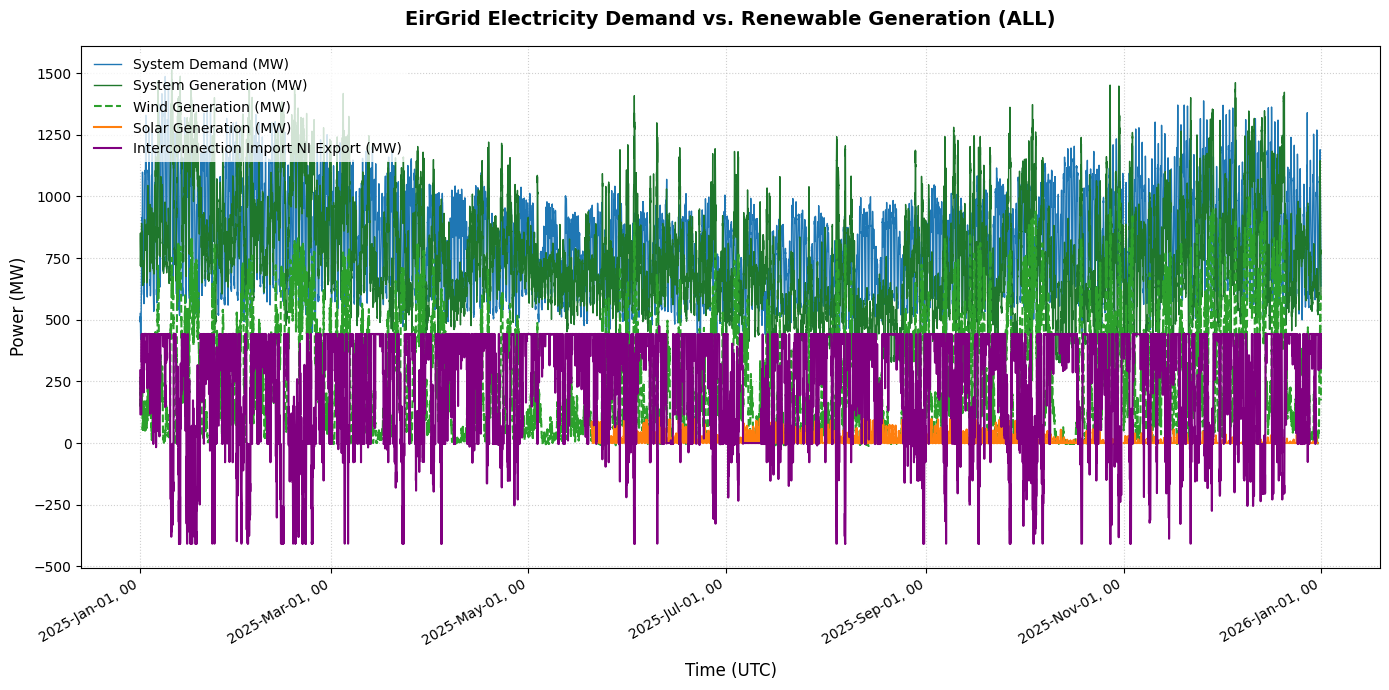

In [78]:
plot_eirgrid_chart(df_new, 'ALL')

In [79]:
df_new.columns

Index(['SYSTEM_DEMAND', 'GEN_EXP', 'WIND_ACTUAL', 'INTER_MOYLE',
       'INTER_NET_NI', 'CO2_INTENSITY', 'CO2_EMISSIONS', 'solar_actual',
       'solar_forecast'],
      dtype='object')

In [80]:
columns_to_sum = ['SYSTEM_DEMAND', 'GEN_EXP', 'WIND_ACTUAL', #'INTER_EWIC', 'INTER_GRNLK',
                  'INTER_MOYLE',
                  'INTER_NET_NI', 'solar_actual']
# 'INTER_MOYLE', 'INTER_NET_NI', 'solar_actual']

# Calculate yearly sums
yearly_sums = df_new[columns_to_sum].sum()


# Calculate monthly sums
monthly_sums = df_new[columns_to_sum].resample('ME').sum()

# Convert yearly sums to GWh
yearly_sums_gwh = yearly_sums * (15 / 60) / 1000

# Calculate null values for relevant columns
null_counts = df_new[columns_to_sum].isnull().sum()

# Get total number of records
total_records = len(df_new)

# Create a DataFrame to display the results for the current year
results_df = pd.DataFrame({
    'Yearly Sum (GWh)': yearly_sums_gwh,
    'Null Values': null_counts
   })

print(f"Total Records: {total_records}")
display(results_df)




Total Records: 35040


,Yearly Sum (GWh),Null Values
SYSTEM_DEMAND,7136.16300,8
GEN_EXP,6688.88400,8
WIND_ACTUAL,2313.15700,8
INTER_MOYLE,2174.08100,8
INTER_NET_NI,2174.08100,8
solar_actual,67.10525,14159


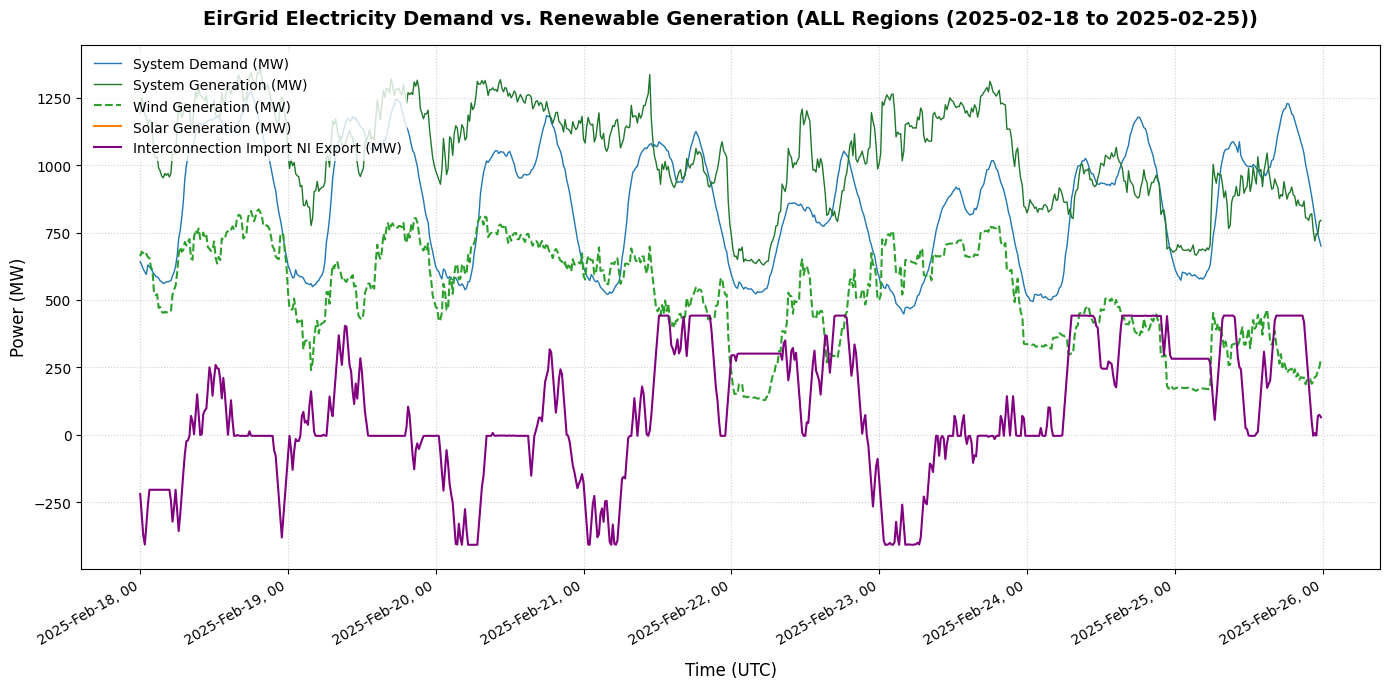

In [81]:
start_plot_date = '2025-02-18'
end_plot_date = '2025-02-25'

# Filter the DataFrame for the specified date range
filtered_df_august = full_year_df_2026.loc[start_plot_date:end_plot_date]

# Plot the filtered data
plot_eirgrid_chart(filtered_df_august, region_label=f"ALL Regions ({start_plot_date} to {end_plot_date})")

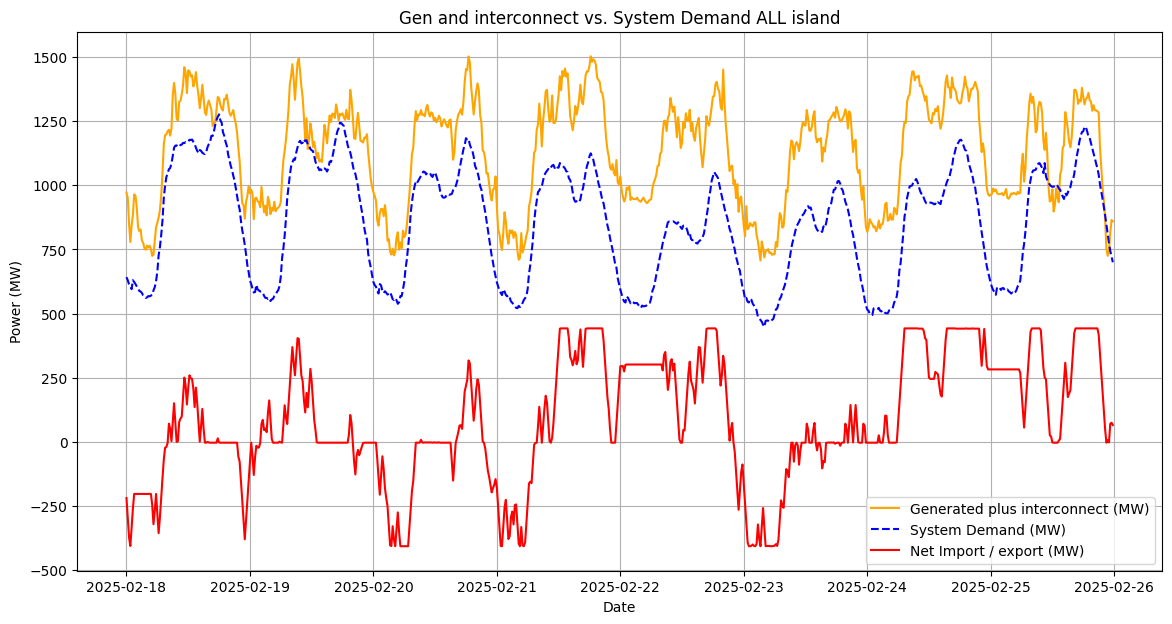

In [83]:
filtered_df_august = full_year_df_2026.loc[start_plot_date:end_plot_date].copy()
filtered_df_august['gen_plus_interconnection'] = filtered_df_august['GEN_EXP'] + filtered_df_august['INTER_NET_NI']
filtered_df_august['wind_plus_solar'] = filtered_df_august['WIND_ACTUAL'] + filtered_df_august['solar_actual']
metrics_to_compare = ['SYSTEM_DEMAND', 'gen_plus_interconnection', 'wind_plus_solar']

plt.figure(figsize=(14, 7))
plt.plot(filtered_df_august.index, filtered_df_august['gen_plus_interconnection'], label='Generated plus interconnect (MW)', color='orange')
plt.plot(filtered_df_august.index, filtered_df_august['SYSTEM_DEMAND'], label='System Demand (MW)', color='blue', linestyle='--')
plt.plot(filtered_df_august.index, filtered_df_august['INTER_NET_NI'], label='Net Import / export (MW)', color='red')

plt.title('Gen and interconnect vs. System Demand ALL island')
plt.xlabel('Date')
plt.ylabel('Power (MW)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Example usage for 2026
years_to_process = [2026]
region = 'ALL'
full_year_ALL_df_2026 = process_eirgrid_data(years_to_process, region)

if not full_year_ALL_df_2026.empty:
    display(full_year_ALL_df_2026.head())
    display(full_year_ALL_df_2026.tail())

Attempting to load data for 2026-01-01 to 2026-01-31 from /content/drive/My Drive/climate/energy2026/eirgrid_ALL_2026-01-01_2026-01-31.csv
Successfully loaded data from CSV for 2026-01-01 to 2026-01-31. Rows: 2976
Attempting to load data for 2026-02-01 to 2026-02-28 from /content/drive/My Drive/climate/energy2026/eirgrid_ALL_2026-02-01_2026-02-28.csv
Successfully loaded data from CSV for 2026-02-01 to 2026-02-28. Rows: 2688
Attempting to load data for 2026-03-01 to 2026-03-31 from /content/drive/My Drive/climate/energy2026/eirgrid_ALL_2026-03-01_2026-03-31.csv
Successfully loaded data from CSV for 2026-03-01 to 2026-03-31. Rows: 2976
Attempting to load data for 2026-04-01 to 2026-04-30 from /content/drive/My Drive/climate/energy2026/eirgrid_ALL_2026-04-01_2026-04-30.csv
Successfully loaded data from CSV for 2026-04-01 to 2026-04-30. Rows: 2880
Attempting to load data for 2026-05-01 to 2026-05-31 from /content/drive/My Drive/climate/energy2026/eirgrid_ALL_2026-05-01_2026-05-31.csv
Succe

,SYSTEM_DEMAND,WIND_ACTUAL,INTER_EWIC,INTER_GRNLK,INTER_MOYLE,INTER_NET,CO2_INTENSITY,solar_actual,solar_forecast
2026-01-01 00:00:00,4487.0,1500.0,530.0,513.0,354.0,1397.0,155.0,4.0,0.0
2026-01-01 00:15:00,4490.0,1532.0,530.0,513.0,353.0,1396.0,153.0,4.0,0.0
2026-01-01 00:30:00,4455.0,1592.0,487.0,513.0,354.0,1354.0,155.0,4.0,0.0
2026-01-01 00:45:00,4398.0,1594.0,415.0,513.0,353.0,1281.0,163.0,4.0,0.0
2026-01-01 01:00:00,4378.0,1578.0,490.0,513.0,354.0,1357.0,163.0,4.0,0.0


,SYSTEM_DEMAND,WIND_ACTUAL,INTER_EWIC,INTER_GRNLK,INTER_MOYLE,INTER_NET,CO2_INTENSITY,solar_actual,solar_forecast
2026-08-30 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2026-08-30 23:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2026-08-30 23:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2026-08-30 23:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2026-08-31 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [37]:
plot_eirgrid_chart(full_year_ALL_df_2026, 'ALL')

NameError: name 'full_year_ALL_df_2026' is not defined

In [ ]:
# Example usage for 2025
years_to_process = [2025]
region = 'ALL'
full_year_all_df_2025 = process_eirgrid_data(years_to_process, region)

if not full_year_all_df_2025.empty:
    display(full_year_all_df_2025.head())
    display(full_year_all_df_2025.tail())

Attempting to load data for 2025-01-01 to 2025-01-31 from /content/drive/My Drive/climate/energy2026/eirgrid_ALL_2025-01-01_2025-01-31.csv
Successfully loaded data from CSV for 2025-01-01 to 2025-01-31. Rows: 2976
Attempting to load data for 2025-02-01 to 2025-02-28 from /content/drive/My Drive/climate/energy2026/eirgrid_ALL_2025-02-01_2025-02-28.csv
Successfully loaded data from CSV for 2025-02-01 to 2025-02-28. Rows: 2688
Attempting to load data for 2025-03-01 to 2025-03-31 from /content/drive/My Drive/climate/energy2026/eirgrid_ALL_2025-03-01_2025-03-31.csv
Successfully loaded data from CSV for 2025-03-01 to 2025-03-31. Rows: 2976
Attempting to load data for 2025-04-01 to 2025-04-30 from /content/drive/My Drive/climate/energy2026/eirgrid_ALL_2025-04-01_2025-04-30.csv
Successfully loaded data from CSV for 2025-04-01 to 2025-04-30. Rows: 2880
Attempting to load data for 2025-05-01 to 2025-05-31 from /content/drive/My Drive/climate/energy2026/eirgrid_ALL_2025-05-01_2025-05-31.csv
Succe

,SYSTEM_DEMAND,WIND_ACTUAL,INTER_EWIC,INTER_GRNLK,INTER_MOYLE,INTER_NET,CO2_INTENSITY,solar_actual,solar_forecast
2025-01-01 00:00:00,4061.0,1989.0,428.0,0.0,294.0,722.0,115.0,NaN,NaN
2025-01-01 00:15:00,4042.0,2059.0,383.0,0.0,222.0,605.0,118.0,NaN,NaN
2025-01-01 00:30:00,3975.0,2144.0,308.0,0.0,148.0,456.0,120.0,NaN,NaN
2025-01-01 00:45:00,3955.0,2303.0,258.0,0.0,116.0,374.0,121.0,NaN,NaN
2025-01-01 01:00:00,3928.0,2305.0,333.0,0.0,116.0,449.0,120.0,NaN,NaN


,SYSTEM_DEMAND,WIND_ACTUAL,INTER_EWIC,INTER_GRNLK,INTER_MOYLE,INTER_NET,CO2_INTENSITY,solar_actual,solar_forecast
2025-12-31 22:45:00,4699.0,1405.0,295.0,513.0,442.0,1250.0,179.0,NaN,NaN
2025-12-31 23:00:00,4645.0,1393.0,314.0,513.0,442.0,1269.0,174.0,NaN,NaN
2025-12-31 23:15:00,4742.0,1417.0,389.0,513.0,442.0,1344.0,169.0,NaN,NaN
2025-12-31 23:30:00,4657.0,1433.0,464.0,513.0,442.0,1419.0,162.0,NaN,NaN
2025-12-31 23:45:00,4598.0,1458.0,530.0,513.0,428.0,1471.0,156.0,NaN,NaN


### Bring all years together ALL

In [23]:
years_to_process = [2023, 2024, 2025, 2026]
region = 'ALL'

# Call the process_eirgrid_data function to get data for all specified years
full_eirgrid_df_2023_2026 = process_eirgrid_data(years_to_process, region)

if not full_eirgrid_df_2023_2026.empty:
    print(f"\nCombined DataFrame for {min(years_to_process)} to {max(years_to_process)} for {region} regions. Total rows: {len(full_eirgrid_df_2023_2026)}")
    print("Head of the combined DataFrame:")
    display(full_eirgrid_df_2023_2026.head())
    print("Tail of the combined DataFrame:")
    display(full_eirgrid_df_2023_2026.tail())
else:
    print("No data was loaded for the specified years and region.")

Attempting to load data for 2023-01-01 to 2023-01-31 from /content/drive/My Drive/climate/energy2026_all/eirgrid_ALL_2023-01-01_2023-01-31.csv
Successfully loaded data from CSV for 2023-01-01 to 2023-01-31. Rows: 2976
Attempting to load data for 2023-02-01 to 2023-02-28 from /content/drive/My Drive/climate/energy2026_all/eirgrid_ALL_2023-02-01_2023-02-28.csv
Successfully loaded data from CSV for 2023-02-01 to 2023-02-28. Rows: 2688
Attempting to load data for 2023-03-01 to 2023-03-31 from /content/drive/My Drive/climate/energy2026_all/eirgrid_ALL_2023-03-01_2023-03-31.csv
Successfully loaded data from CSV for 2023-03-01 to 2023-03-31. Rows: 2976
Attempting to load data for 2023-04-01 to 2023-04-30 from /content/drive/My Drive/climate/energy2026_all/eirgrid_ALL_2023-04-01_2023-04-30.csv
Successfully loaded data from CSV for 2023-04-01 to 2023-04-30. Rows: 2880
Attempting to load data for 2023-05-01 to 2023-05-31 from /content/drive/My Drive/climate/energy2026_all/eirgrid_ALL_2023-05-01_

,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,CO2_INTENSITY,CO2_EMISSIONS,solar_actual,solar_forecast,INTER_EWIC,INTER_MOYLE,INTER_NET,INTER_GRNLK
2023-01-01 00:00:00,4024.0,3043.0,664.0,255.0,1026.0,NaN,NaN,NaN,NaN,NaN,NaN
2023-01-01 00:15:00,4013.0,3035.0,729.0,253.0,1016.0,NaN,NaN,NaN,NaN,NaN,NaN
2023-01-01 00:30:00,3969.0,2993.0,697.0,247.0,981.0,NaN,NaN,NaN,NaN,NaN,NaN
2023-01-01 00:45:00,3907.0,3001.0,693.0,255.0,996.0,NaN,NaN,NaN,NaN,NaN,NaN
2023-01-01 01:00:00,3876.0,3045.0,697.0,251.0,972.0,NaN,NaN,NaN,NaN,NaN,NaN


Tail of the combined DataFrame:


,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,CO2_INTENSITY,CO2_EMISSIONS,solar_actual,solar_forecast,INTER_EWIC,INTER_MOYLE,INTER_NET,INTER_GRNLK
2026-09-29 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-29 23:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-29 23:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-29 23:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-30 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


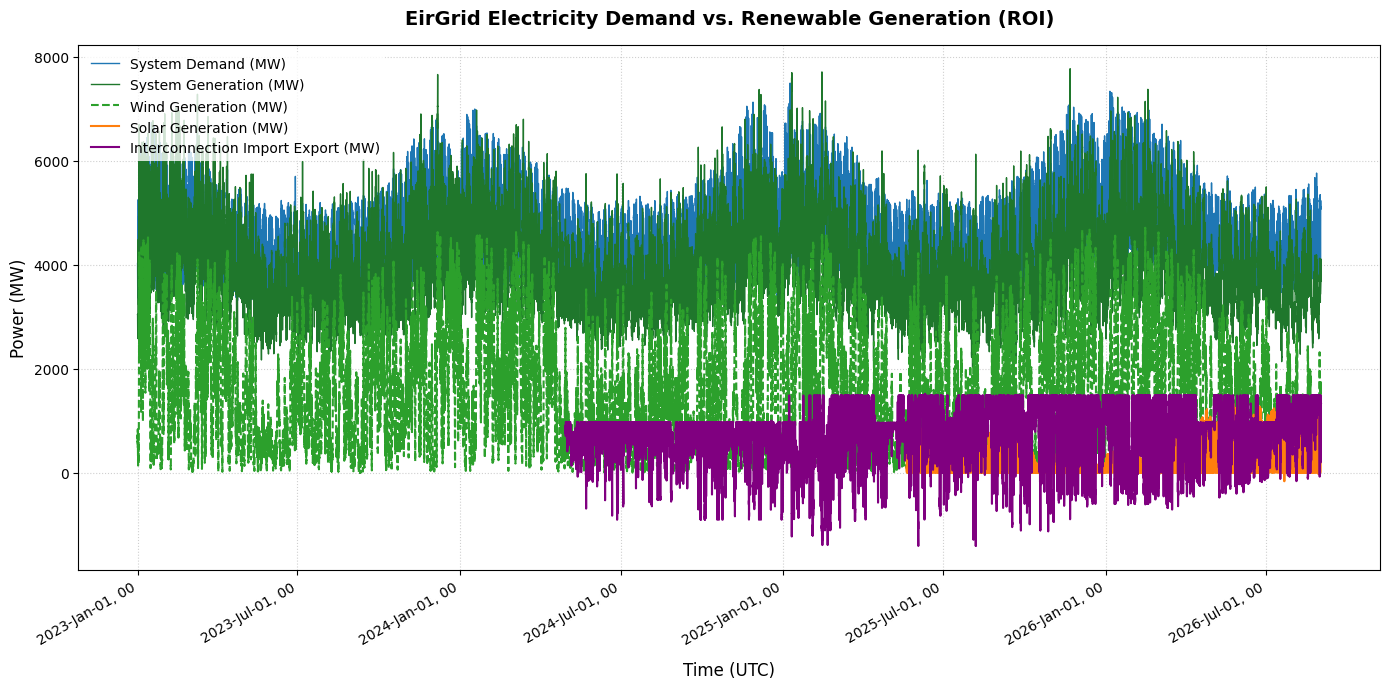

In [29]:
plot_eirgrid_chart(full_eirgrid_df_2023_2026)

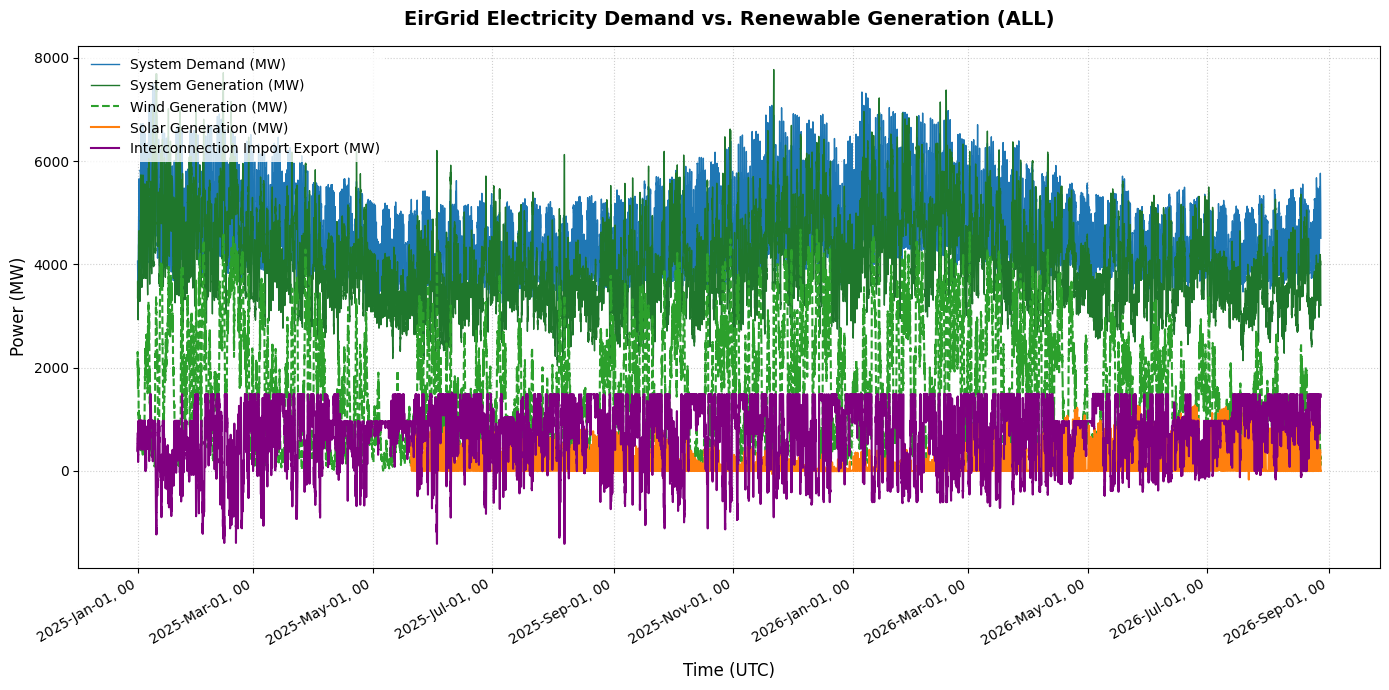

In [30]:
# Zoom in to 2025 - 2026
start_date = f"2025-01-01"
end_date = f"2026-08-27"
df_year = full_eirgrid_df_2023_2026.loc[start_date:end_date]
plot_eirgrid_chart(df_year, 'ALL')

In [31]:
years_to_process = [2023, 2024, 2025, 2026]
columns_to_sum = ['SYSTEM_DEMAND', 'GEN_EXP', 'WIND_ACTUAL', 'solar_actual',  'INTER_NET']

display(full_eirgrid_df_2023_2026.isnull().sum())



,0
SYSTEM_DEMAND,2756
GEN_EXP,2756
WIND_ACTUAL,2756
CO2_INTENSITY,2760
CO2_EMISSIONS,23268
solar_actual,87826
solar_forecast,87416
INTER_EWIC,49260
INTER_MOYLE,49260
INTER_NET,49260


### Bring all years together ROI

In [47]:
years_to_process = [2023, 2024, 2025, 2026]
region = 'ROI'

# Call the process_eirgrid_data function to get data for all specified years
roi_eirgrid_df_2023_2026 = process_eirgrid_data(years_to_process, region)

if not roi_eirgrid_df_2023_2026.empty:
    print(f"\nCombined DataFrame for {min(years_to_process)} to {max(years_to_process)} for {region} regions. Total rows: {len(roi_eirgrid_df_2023_2026)}")
    print("Head of the combined DataFrame:")
    display(roi_eirgrid_df_2023_2026.head())
    print("Tail of the combined DataFrame:")
    display(roi_eirgrid_df_2023_2026.tail())
else:
    print("No data was loaded for the specified years and region.")

Attempting to load data for 2023-01-01 to 2023-01-31 from /content/drive/My Drive/climate/energy2026_all/eirgrid_ROI_2023-01-01_2023-01-31.csv
Successfully loaded data from CSV for 2023-01-01 to 2023-01-31. Rows: 2976
Attempting to load data for 2023-02-01 to 2023-02-28 from /content/drive/My Drive/climate/energy2026_all/eirgrid_ROI_2023-02-01_2023-02-28.csv
Successfully loaded data from CSV for 2023-02-01 to 2023-02-28. Rows: 2688
Attempting to load data for 2023-03-01 to 2023-03-31 from /content/drive/My Drive/climate/energy2026_all/eirgrid_ROI_2023-03-01_2023-03-31.csv
Successfully loaded data from CSV for 2023-03-01 to 2023-03-31. Rows: 2976
Attempting to load data for 2023-04-01 to 2023-04-30 from /content/drive/My Drive/climate/energy2026_all/eirgrid_ROI_2023-04-01_2023-04-30.csv
Successfully loaded data from CSV for 2023-04-01 to 2023-04-30. Rows: 2880
Attempting to load data for 2023-05-01 to 2023-05-31 from /content/drive/My Drive/climate/energy2026_all/eirgrid_ROI_2023-05-01_

,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,CO2_INTENSITY,CO2_EMISSIONS,solar_actual,solar_forecast,INTER_EWIC,INTER_NET_ROI,INTER_GRNLK
2023-01-01 00:00:00,3322.0,2490.0,588.0,253.0,840.0,NaN,NaN,NaN,NaN,NaN
2023-01-01 00:15:00,3316.0,2483.0,667.0,249.0,827.0,NaN,NaN,NaN,NaN,NaN
2023-01-01 00:30:00,3286.0,2475.0,652.0,243.0,798.0,NaN,NaN,NaN,NaN,NaN
2023-01-01 00:45:00,3232.0,2480.0,658.0,250.0,807.0,NaN,NaN,NaN,NaN,NaN
2023-01-01 01:00:00,3204.0,2527.0,670.0,244.0,782.0,NaN,NaN,NaN,NaN,NaN


Tail of the combined DataFrame:


,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,CO2_INTENSITY,CO2_EMISSIONS,solar_actual,solar_forecast,INTER_EWIC,INTER_NET_ROI,INTER_GRNLK
2026-09-29 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-29 23:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-29 23:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-29 23:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-30 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [53]:
years_to_process = [2023, 2024, 2025, 2026]
columns_to_sum = ['SYSTEM_DEMAND', 'GEN_EXP', 'WIND_ACTUAL', 'solar_actual',  'INTER_NET_ROI']

display(roi_eirgrid_df_2023_2026.isnull().sum())

,0
SYSTEM_DEMAND,2669
GEN_EXP,2669
WIND_ACTUAL,2669
CO2_INTENSITY,2747
CO2_EMISSIONS,17899
solar_actual,87739
solar_forecast,87344
INTER_EWIC,49173
INTER_NET_ROI,49173
INTER_GRNLK,69338


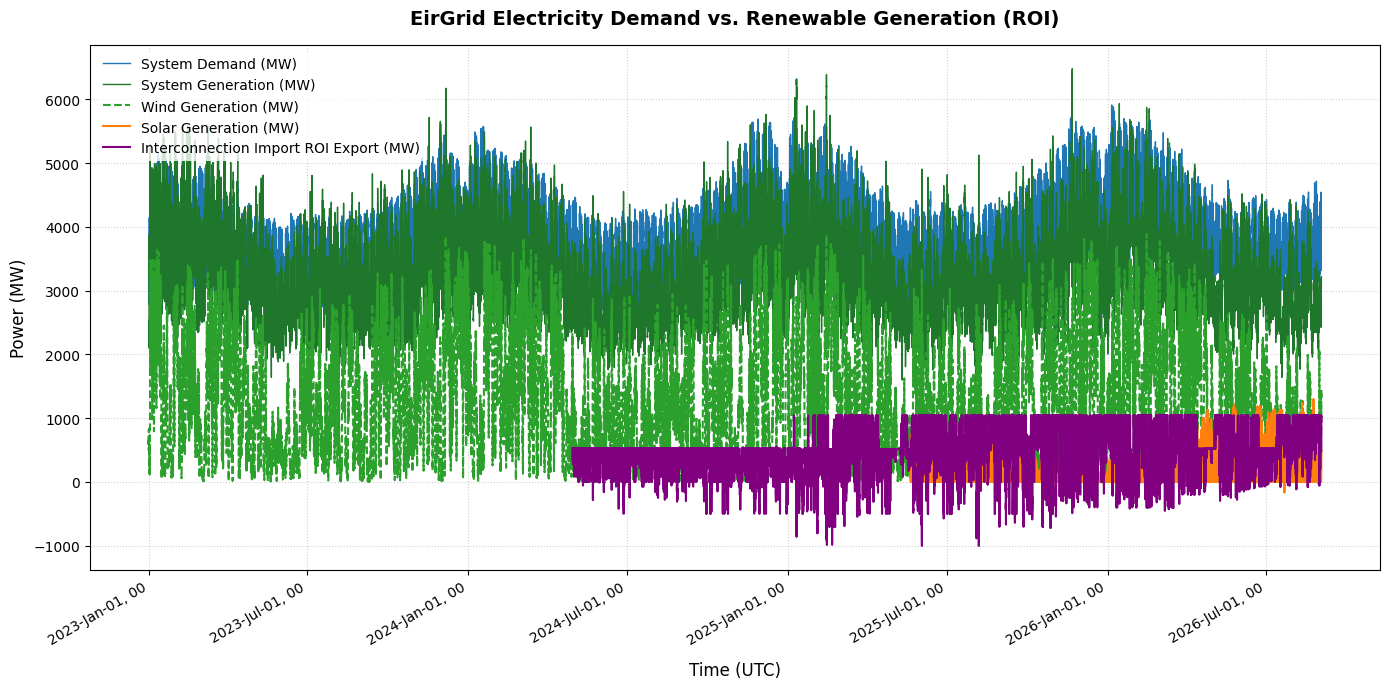

In [50]:
plot_eirgrid_chart(roi_eirgrid_df_2023_2026)

In [55]:
columns_for_analysis = ['SYSTEM_DEMAND', 'GEN_EXP', 'WIND_ACTUAL', 'solar_actual', 'INTER_NET_ROI']

for year in years_to_process:
    print(f"\n--- Analysis for Year {year} ---")

    # Filter data for the current year
    df_year = roi_eirgrid_df_2023_2026.loc[str(year)]

    # Calculate yearly sums in GWh
    # Assuming data is 15-minute intervals, so each value represents MW * (15/60) hours = MW * 0.25 hours
    # To convert MW to GWh: MW * 0.25 hours / 1000 = GWh
    yearly_sums_gwh = (df_year[columns_for_analysis].sum()) * (15 / 60) / 1000

    # Calculate null values for relevant columns
    null_counts = df_year[columns_for_analysis].isnull().sum()

    # Get total number of records
    total_records = len(df_year)

    # Create a DataFrame to display the results for the current year
    results_df = pd.DataFrame({
        'Yearly Sum (GWh)': yearly_sums_gwh,
        'Null Values': null_counts
    })

    print(f"Total Records: {total_records}")
    display(results_df)


--- Analysis for Year 2023 ---
Total Records: 35040


,Yearly Sum (GWh),Null Values
SYSTEM_DEMAND,32472.0455,13
GEN_EXP,29383.5025,13
WIND_ACTUAL,11393.3315,13
solar_actual,0.0000,35040
INTER_NET_ROI,0.0000,35040



--- Analysis for Year 2024 ---
Total Records: 35132


,Yearly Sum (GWh),Null Values
SYSTEM_DEMAND,33697.90250,0
GEN_EXP,28850.62900,0
WIND_ACTUAL,11124.90925,0
solar_actual,0.00000,35132
INTER_NET_ROI,1965.54075,11477



--- Analysis for Year 2025 ---
Total Records: 35040


,Yearly Sum (GWh),Null Values
SYSTEM_DEMAND,34561.56000,8
GEN_EXP,28747.88675,8
WIND_ACTUAL,11319.58400,8
solar_actual,648.76300,14159
INTER_NET_ROI,4502.95625,8



--- Analysis for Year 2026 ---
Total Records: 26113


,Yearly Sum (GWh),Null Values
SYSTEM_DEMAND,23567.95875,2648
GEN_EXP,19281.18475,2648
WIND_ACTUAL,7458.91525,2648
solar_actual,1202.30250,3408
INTER_NET_ROI,3207.09125,2648


### Compare yearly GWH values

In [56]:
full_eirgrid_df_2023_2026.columns

Index(['SYSTEM_DEMAND', 'GEN_EXP', 'WIND_ACTUAL', 'CO2_INTENSITY',
       'CO2_EMISSIONS', 'solar_actual', 'solar_forecast', 'INTER_EWIC',
       'INTER_MOYLE', 'INTER_NET', 'INTER_GRNLK'],
      dtype='object')

In [57]:
columns_for_analysis = ['SYSTEM_DEMAND', 'GEN_EXP', 'WIND_ACTUAL', 'INTER_EWIC', 'INTER_GRNLK', 'INTER_MOYLE', 'INTER_NET', 'solar_actual']

for year in years_to_process:
    print(f"\n--- Analysis for Year {year} ---")

    # Filter data for the current year
    df_year = full_eirgrid_df_2023_2026.loc[str(year)]

    # Calculate yearly sums in GWh
    # Assuming data is 15-minute intervals, so each value represents MW * (15/60) hours = MW * 0.25 hours
    # To convert MW to GWh: MW * 0.25 hours / 1000 = GWh
    yearly_sums_gwh = (df_year[columns_for_analysis].sum()) * (15 / 60) / 1000

    # Calculate null values for relevant columns
    null_counts = df_year[columns_for_analysis].isnull().sum()

    # Get total number of records
    total_records = len(df_year)

    # Create a DataFrame to display the results for the current year
    results_df = pd.DataFrame({
        'Yearly Sum (GWh)': yearly_sums_gwh,
        'Null Values': null_counts
    })

    print(f"Total Records: {total_records}")
    display(results_df)


--- Analysis for Year 2023 ---
Total Records: 35040


,Yearly Sum (GWh),Null Values
SYSTEM_DEMAND,39641.31225,13
GEN_EXP,36379.96125,13
WIND_ACTUAL,13724.26875,13
INTER_EWIC,0.00000,35040
INTER_GRNLK,0.00000,35040
INTER_MOYLE,0.00000,35040
INTER_NET,0.00000,35040
solar_actual,0.00000,35040



--- Analysis for Year 2024 ---
Total Records: 35132


,Yearly Sum (GWh),Null Values
SYSTEM_DEMAND,40891.41725,0
GEN_EXP,36154.62425,0
WIND_ACTUAL,13264.94275,0
INTER_EWIC,1965.63150,11477
INTER_GRNLK,-0.09075,31642
INTER_MOYLE,1711.50125,11477
INTER_NET,3677.04200,11477
solar_actual,0.00000,35132



--- Analysis for Year 2025 ---
Total Records: 35040


,Yearly Sum (GWh),Null Values
SYSTEM_DEMAND,41696.24950,8
GEN_EXP,35436.78325,8
WIND_ACTUAL,13632.49750,8
INTER_EWIC,1694.94300,8
INTER_GRNLK,2808.01325,8
INTER_MOYLE,2174.08100,8
INTER_NET,6677.03725,8
solar_actual,715.66675,14159



--- Analysis for Year 2026 ---
Total Records: 26113


,Yearly Sum (GWh),Null Values
SYSTEM_DEMAND,28214.99150,2735
GEN_EXP,23829.22950,2735
WIND_ACTUAL,9112.13100,2735
INTER_EWIC,1262.41400,2735
INTER_GRNLK,1924.57225,2735
INTER_MOYLE,1555.40225,2735
INTER_NET,4742.38850,2735
solar_actual,1287.70625,3495


from CSO: Ireland’s electricity grid supply grew by 3.5% to 35,884 GWh in 2025 compared with a supply of 34,684 GWh in 2024. The increase in supply largely came from increases in net imports of electricity.

In 2025, net imports of electricity were 6,130 GWh, which made up 17% of grid supply. Net imports of electricity rose by 21% in 2025 compared with 2024, and by 87% when comparing with 2023.

,2023,2024,2025,2026
SYSTEM_DEMAND,39641.31225,40891.41725,41696.24950,28214.99150
GEN_EXP,36379.96125,36154.62425,35436.78325,23829.22950
WIND_ACTUAL,13724.26875,13264.94275,13632.49750,9112.13100
solar_actual,0.00000,0.00000,715.66675,1287.70625
INTER_NET,0.00000,3677.04200,6677.03725,4742.38850
IMPORTS,0.00000,3870.83625,7111.74175,4922.59900
EXPORTS,0.00000,193.79425,434.70450,180.21050


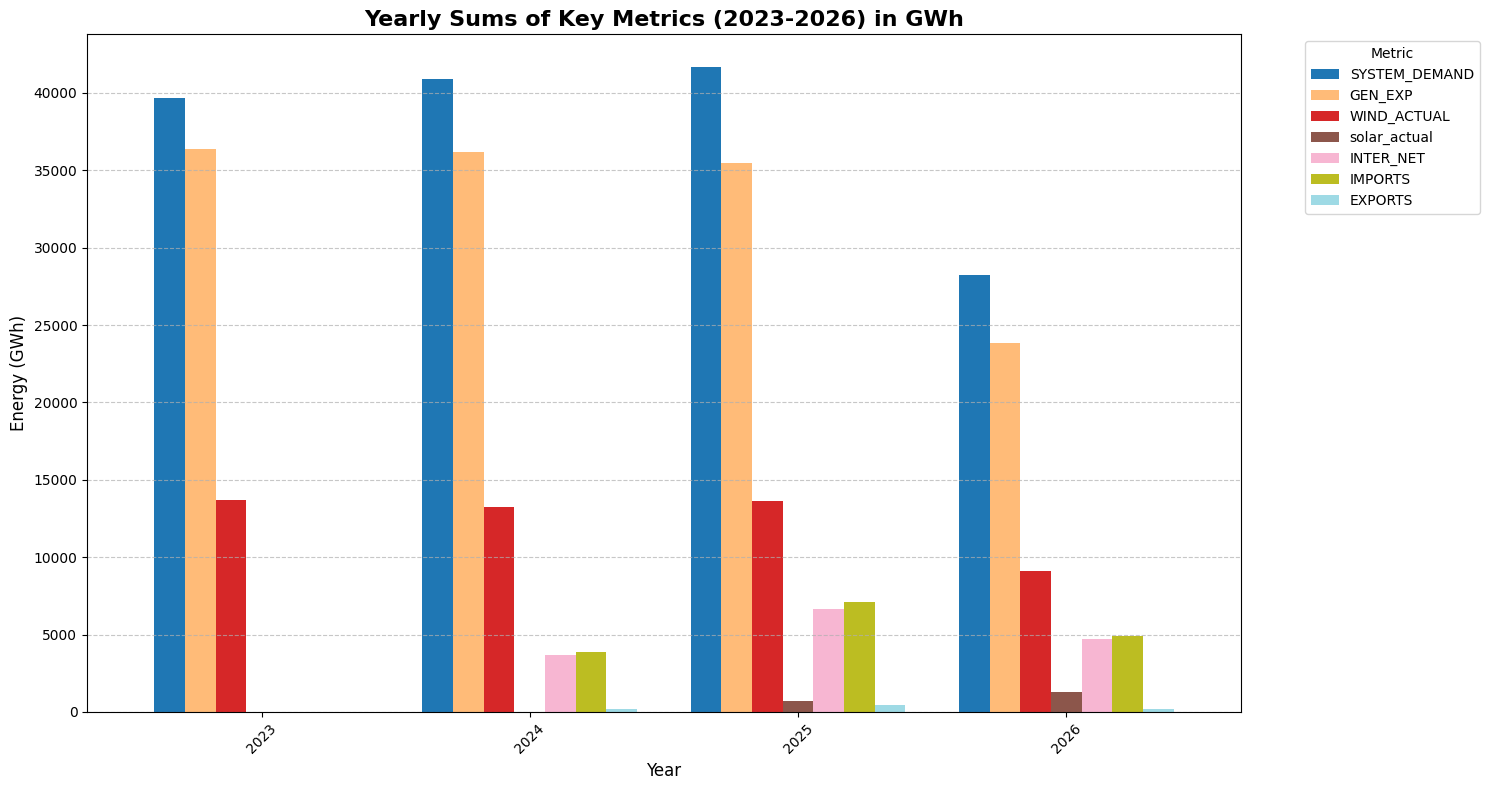

In [58]:
columns_for_analysis = ['SYSTEM_DEMAND', 'GEN_EXP', 'WIND_ACTUAL', 'solar_actual',  'INTER_NET']

yearly_sums_gwh_all_years = {}

for year in years_to_process:
    df_year = full_eirgrid_df_2023_2026.loc[str(year)]

    # Calculate original yearly sums in GWh
    yearly_sums_gwh = (df_year[columns_for_analysis].sum()) * (15 / 60) / 1000

    # Calculate Imports and Exports from INTER_NET
    # Imports: sum of positive INTER_NET values
    imports_mw = df_year['INTER_NET'].apply(lambda x: x if x > 0 else 0).sum()
    # Exports: sum of absolute negative INTER_NET values
    exports_mw = df_year['INTER_NET'].apply(lambda x: abs(x) if x < 0 else 0).sum()

    yearly_imports_gwh = imports_mw * (15 / 60) / 1000
    yearly_exports_gwh = exports_mw * (15 / 60) / 1000

    # Add Imports and Exports to the yearly_sums_gwh series
    yearly_sums_gwh['IMPORTS'] = yearly_imports_gwh
    yearly_sums_gwh['EXPORTS'] = yearly_exports_gwh

    yearly_sums_gwh_all_years[year] = yearly_sums_gwh

# Convert the dictionary of series to a DataFrame
yearly_gwh_df = pd.DataFrame(yearly_sums_gwh_all_years)

display(yearly_gwh_df)

# Plotting the data
fig, ax = plt.subplots(figsize=(15, 8))
yearly_gwh_df.T.plot(kind='bar', ax=ax, colormap='tab20', width=0.8)

ax.set_title('Yearly Sums of Key Metrics (2023-2026) in GWh', fontsize=16, fontweight='bold')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Energy (GWh)', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(title='Metric', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [61]:
full_eirgrid_df_2023_2026.columns

Index(['SYSTEM_DEMAND', 'GEN_EXP', 'WIND_ACTUAL', 'CO2_INTENSITY',
       'CO2_EMISSIONS', 'solar_actual', 'solar_forecast', 'INTER_EWIC',
       'INTER_MOYLE', 'INTER_NET', 'INTER_GRNLK'],
      dtype='object')

,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,solar_actual,INTER_NET
2023-01-31,3634.68050,3530.82575,1478.54875,0.00000,0.00000
2023-02-28,3213.54950,3178.78025,1361.23550,0.00000,0.00000
2023-03-31,3595.90800,3403.87000,1300.62050,0.00000,0.00000
2023-04-30,3217.83600,3034.04700,1112.44650,0.00000,0.00000
2023-05-31,3181.67475,2750.73550,666.29025,0.00000,0.00000
2023-06-30,3015.71800,2610.44350,632.44225,0.00000,0.00000
2023-07-31,3060.00175,2724.65425,995.91675,0.00000,0.00000
2023-08-31,3113.27675,2832.22025,1042.64575,0.00000,0.00000
2023-09-30,3121.23025,2781.93250,996.22725,0.00000,0.00000
2023-10-31,3359.94175,2874.28750,1014.34200,0.00000,0.00000


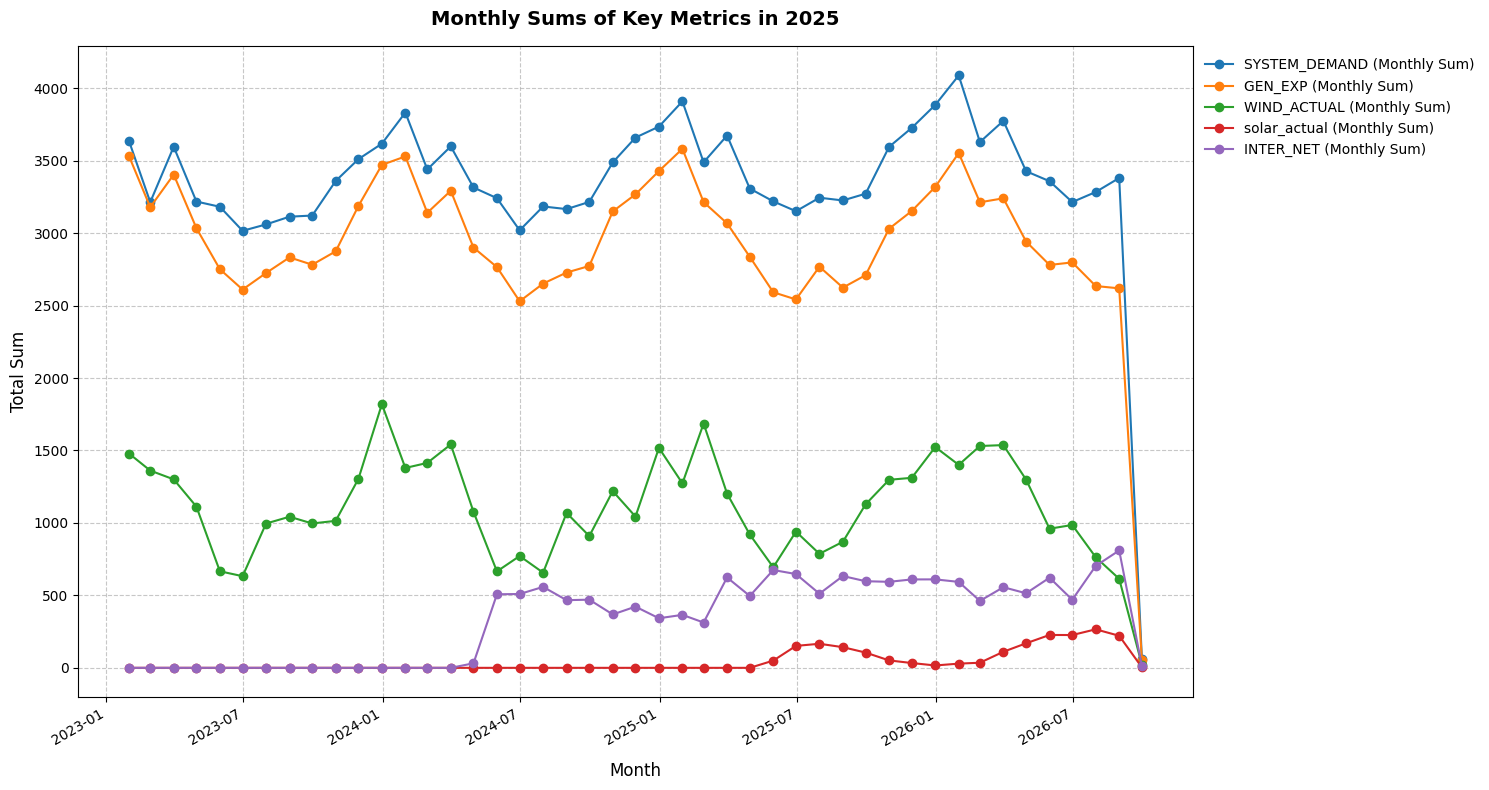

In [63]:
columns_for_analysis = ['SYSTEM_DEMAND', 'GEN_EXP', 'WIND_ACTUAL', 'solar_actual',  'INTER_NET']

# Calculate monthly sums
monthly_sums = full_eirgrid_df_2023_2026[columns_for_analysis].resample('ME').sum()



monthly_sums_gwh = monthly_sums * (15 / 60) / 1000

# Convert the dictionary of series to a DataFrame
monthly_gwh_df = pd.DataFrame(monthly_sums_gwh)

display(monthly_gwh_df.head())

# Plotting all monthly sums on a single chart
fig, ax = plt.subplots(1, 1, figsize=(15, 8))

for column in columns_for_analysis:
    ax.plot(monthly_gwh_df.index, monthly_gwh_df[column], marker='o', linestyle='-', label=f'{column} (Monthly Sum)')

ax.set_title('Monthly Sums of Key Metrics in 2025', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Month', fontsize=12, labelpad=10)
ax.set_ylabel('Total Sum', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=True, facecolor='white', edgecolor='none') # Place legend outside

# Format x-axis (dates)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate() # Rotates date labels for readability

plt.tight_layout()
plt.show()


### Yearly Jan-Aug total values

,2023,2024,2025,2026
SYSTEM_DEMAND,20962.95525,21726.75250,22244.42525,23061.15950
GEN_EXP,19187.18475,18396.83725,18485.59975,18923.10525
WIND_ACTUAL,7042.64175,7116.17525,6842.46175,7361.09825
solar_actual,0.00000,0.00000,451.44700,1178.87700
INTER_NET_ROI,0.00000,1103.77500,2815.65875,3090.55275


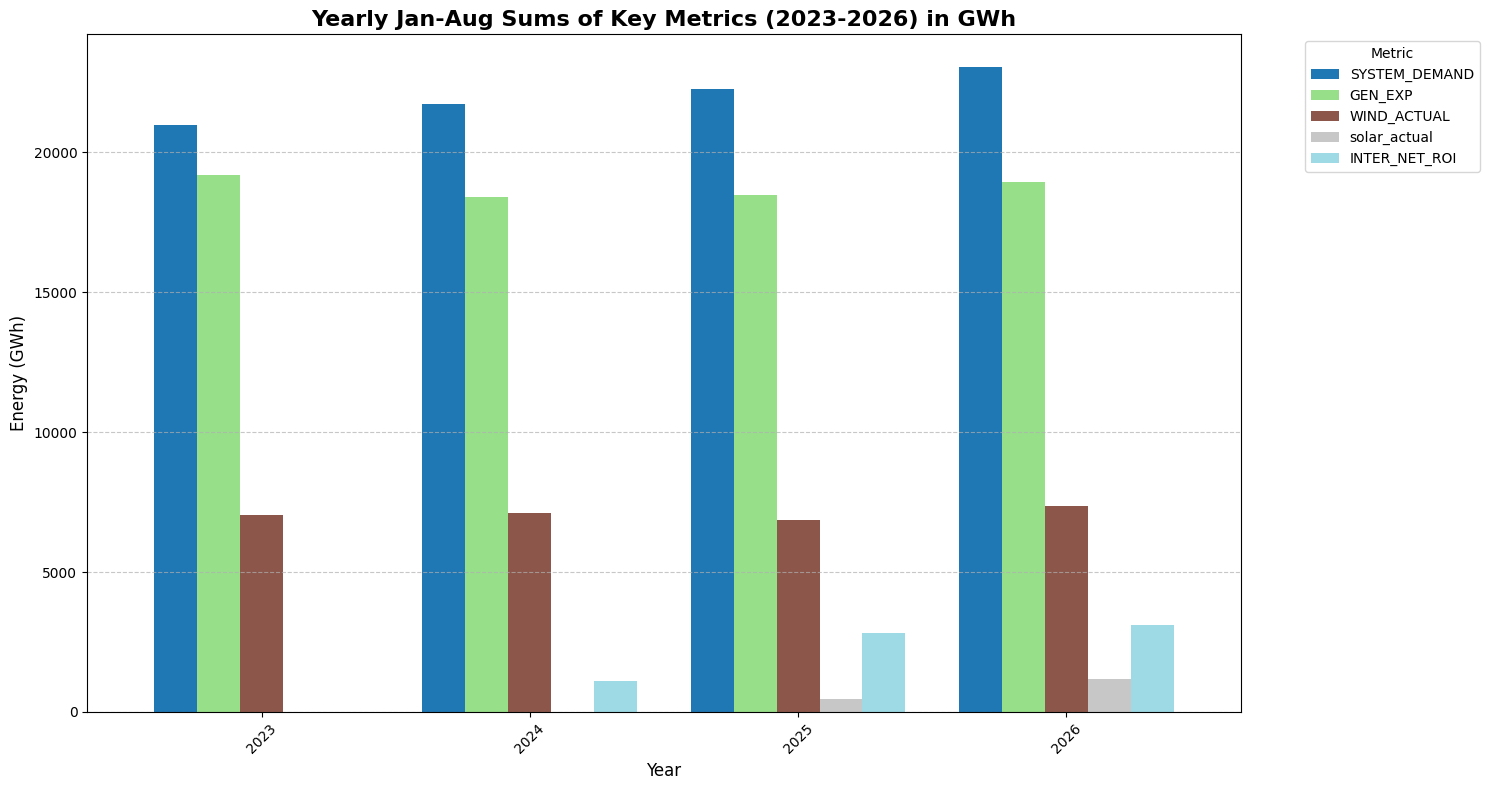

In [66]:
columns_for_analysis = ['SYSTEM_DEMAND', 'GEN_EXP',  'WIND_ACTUAL', 'solar_actual', 'INTER_NET_ROI']
years_to_process = [2023, 2024, 2025, 2026]

yearly_sums_gwh_all_years = {}

for year in years_to_process:
    start_date = f"{year}-01-01"
    end_date = f"{year}-08-27"
    df_year = roi_eirgrid_df_2023_2026.loc[start_date:end_date]
    yearly_sums_gwh = (df_year[columns_for_analysis].sum()) * (15 / 60) / 1000
    yearly_sums_gwh_all_years[year] = yearly_sums_gwh

# Convert the dictionary of series to a DataFrame
yearly_gwh_df = pd.DataFrame(yearly_sums_gwh_all_years)

display(yearly_gwh_df)

# Plotting the data
fig, ax = plt.subplots(figsize=(15, 8))
yearly_gwh_df.T.plot(kind='bar', ax=ax, colormap='tab20', width=0.8)

ax.set_title('Yearly Jan-Aug Sums of Key Metrics (2023-2026) in GWh', fontsize=16, fontweight='bold')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Energy (GWh)', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(title='Metric', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

,2023,2024,2025,2026
SYSTEM_DEMAND,25612.67625,26373.89925,26807.17375,27712.38650
GEN_EXP,23697.56575,23159.24650,22845.59250,23454.15575
WIND_ACTUAL,8513.74150,8481.73750,8160.64350,9021.44025
solar_actual,0.00000,0.00000,498.95175,1266.11425
INTER_NET,0.00000,2026.43550,4231.24325,4606.63300


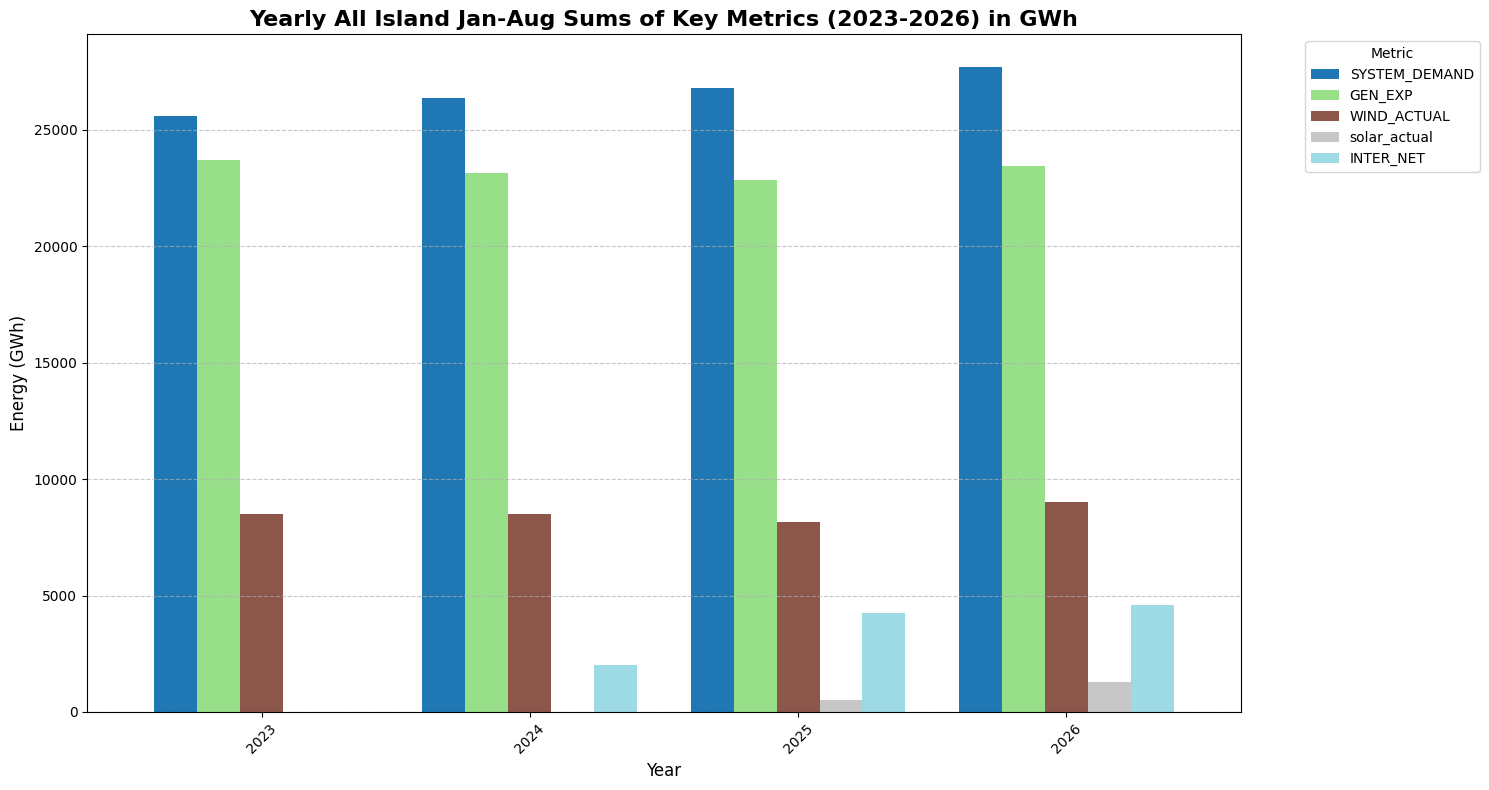

In [73]:
all_columns_for_analysis = ['SYSTEM_DEMAND', 'GEN_EXP',  'WIND_ACTUAL', 'solar_actual', 'INTER_NET']
years_to_process = [2023, 2024, 2025, 2026]

all_yearly_sums_gwh_all_years = {}

for year in years_to_process:
    start_date = f"{year}-01-01"
    end_date = f"{year}-08-27"
    df_year = full_eirgrid_df_2023_2026.loc[start_date:end_date]
    yearly_sums_gwh = (df_year[all_columns_for_analysis].sum()) * (15 / 60) / 1000
    all_yearly_sums_gwh_all_years[year] = yearly_sums_gwh

# Convert the dictionary of series to a DataFrame
all_yearly_gwh_df = pd.DataFrame(all_yearly_sums_gwh_all_years)

display(all_yearly_gwh_df)

# Plotting the data
fig, ax = plt.subplots(figsize=(15, 8))
all_yearly_gwh_df.T.plot(kind='bar', ax=ax, colormap='tab20', width=0.8)

ax.set_title('Yearly All Island Jan-Aug Sums of Key Metrics (2023-2026) in GWh', fontsize=16, fontweight='bold')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Energy (GWh)', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(title='Metric', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [67]:
yearly_gwh_df.head()


,2023,2024,2025,2026
SYSTEM_DEMAND,20962.95525,21726.75250,22244.42525,23061.15950
GEN_EXP,19187.18475,18396.83725,18485.59975,18923.10525
WIND_ACTUAL,7042.64175,7116.17525,6842.46175,7361.09825
solar_actual,0.00000,0.00000,451.44700,1178.87700
INTER_NET_ROI,0.00000,1103.77500,2815.65875,3090.55275


In [69]:
from types import new_class
new_df = yearly_gwh_df.T.copy()


new_df['wind_pct'] = new_df.WIND_ACTUAL  / new_df.SYSTEM_DEMAND * 100
new_df['solar_pct'] = new_df.solar_actual  / new_df.SYSTEM_DEMAND * 100
new_df['interconnection_pct'] = new_df.INTER_NET_ROI  / new_df.SYSTEM_DEMAND * 100
new_df.head()

,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,solar_actual,INTER_NET_ROI,wind_pct,solar_pct,interconnection_pct
2023,20962.95525,19187.18475,7042.64175,0.000,0.00000,33.595653,0.000000,0.000000
2024,21726.75250,18396.83725,7116.17525,0.000,1103.77500,32.753055,0.000000,5.080258
2025,22244.42525,18485.59975,6842.46175,451.447,2815.65875,30.760344,2.029484,12.657817
2026,23061.15950,18923.10525,7361.09825,1178.877,3090.55275,31.919897,5.111959,13.401550


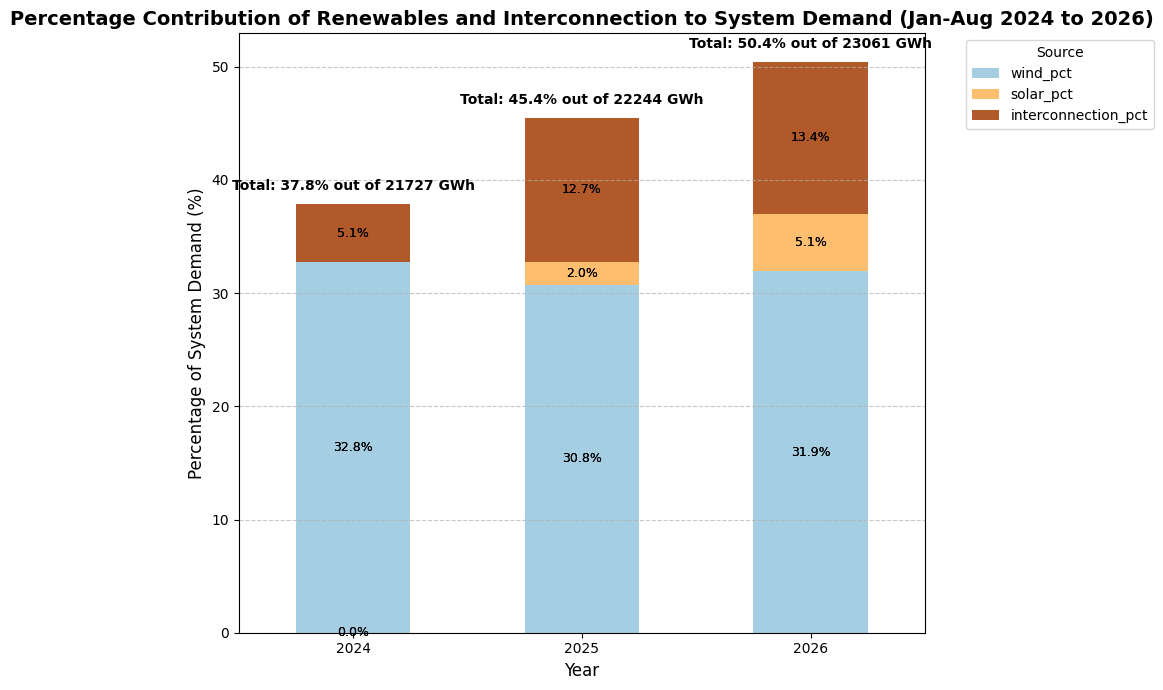

<Figure size 640x480 with 0 Axes>

In [70]:
import matplotlib.pyplot as plt
import numpy as np

# Create a DataFrame for plotting percentages
plot_data = new_df[['wind_pct', 'solar_pct', 'interconnection_pct']].loc[2024:2026]
# Plotting
fig, ax = plt.subplots(figsize=(10, 7))

plot_data.plot(kind='bar', stacked=True, ax=ax, colormap='Paired')

ax.set_title('Percentage Contribution of Renewables and Interconnection to System Demand (Jan-Aug 2024 to 2026)', fontsize=14, fontweight='bold')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Percentage of System Demand (%)', fontsize=12)
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(title='Source', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add total percentage labels on top of each bar
for container in ax.containers:
    labels = [f'{w:.1f}%' for w in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=9)

# Add total percentage labels on top of each bar
for container in ax.containers:
    labels = [f'{w:.1f}%' for w in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=9)

# Calculate total renewable percentage for each year
total_renewable_pct_2024 = plot_data.loc[2024].sum()
total_renewable_pct_2025 = plot_data.loc[2025].sum()
total_renewable_pct_2026 = plot_data.loc[2026].sum()

ax.text(0, total_renewable_pct_2024 + 1, f'Total: {total_renewable_pct_2024:.1f}% out of {new_df.loc[2024].SYSTEM_DEMAND:.0f} GWh', ha='center', va='bottom', fontweight='bold')
ax.text(1, total_renewable_pct_2025 + 1, f'Total: {total_renewable_pct_2025:.1f}% out of {new_df.loc[2025].SYSTEM_DEMAND:.0f} GWh', ha='center', va='bottom', fontweight='bold')
ax.text(2, total_renewable_pct_2026 + 1, f'Total: {total_renewable_pct_2026:.1f}% out of {new_df.loc[2026].SYSTEM_DEMAND:.0f} GWh', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


plt.tight_layout()
plt.show()

In [ ]:
new_df.loc[2024].SYSTEM_DEMAND


np.float64(26373.89925)

### Yearly and Monthly Sums for Key Metrics ROI (2025)

In [ ]:
columns_to_sum = ['SYSTEM_DEMAND', 'WIND_ACTUAL', 'INTER_EWIC', 'INTER_GRNLK', 'INTER_NET_ROI', 'solar_actual']

# Calculate yearly sums
yearly_sums = full_year_df_2025[columns_to_sum].sum()


# Calculate monthly sums
monthly_sums = full_year_df_2025[columns_to_sum].resample('ME').sum()

# Convert yearly sums to GWh
yearly_sums_gwh = yearly_sums * (15 / 60) / 1000

print("\nYearly Sums for ROI 2025 (in GWh):")
display(yearly_sums_gwh)


Yearly Sums for 2025 (in GWh):


,0
SYSTEM_DEMAND,34561.56000
WIND_ACTUAL,11319.58400
INTER_EWIC,1694.94300
INTER_GRNLK,2808.01325
INTER_NET_ROI,4502.95625
solar_actual,648.76300


In [ ]:
columns_to_sum = ['SYSTEM_DEMAND', 'WIND_ACTUAL', 'INTER_MOYLE', 'INTER_NET_NI', 'solar_actual']

# Calculate yearly sums
yearly_sums = full_year_ni_df_2025[columns_to_sum].sum()


# Calculate monthly sums
monthly_sums = full_year_ni_df_2025[columns_to_sum].resample('ME').sum()

# Convert yearly sums to GWh
yearly_sums_gwh = yearly_sums * (15 / 60) / 1000

print("\nYearly Sums for NI 2025 (in GWh):")
display(yearly_sums_gwh)


Yearly Sums for NI 2025 (in GWh):


,0
SYSTEM_DEMAND,7136.16300
WIND_ACTUAL,2313.15700
INTER_MOYLE,2174.08100
INTER_NET_NI,2174.08100
solar_actual,67.10525


In [ ]:


columns_to_sum = ['SYSTEM_DEMAND', 'WIND_ACTUAL', 'INTER_EWIC', 'INTER_GRNLK', 'INTER_MOYLE', 'INTER_NET', 'solar_actual']

# Calculate yearly sums
yearly_sums = full_year_all_df_2025[columns_to_sum].sum()


# Calculate monthly sums
monthly_sums = full_year_all_df_2025[columns_to_sum].resample('ME').sum()

# Convert yearly sums to GWh
yearly_sums_gwh = yearly_sums * (15 / 60) / 1000

print("\nYearly Sums for NI 2025 (in GWh):")
display(yearly_sums_gwh)


Yearly Sums for NI 2025 (in GWh):


,0
SYSTEM_DEMAND,41696.24950
WIND_ACTUAL,13632.49750
INTER_EWIC,1694.94300
INTER_GRNLK,2808.01325
INTER_MOYLE,2174.08100
INTER_NET,6677.03725
solar_actual,715.66675


These values now represent the total energy generated or consumed in GWh for each category over the year 2025. You can see, for example, that the total system demand for 2025 is approximately 34,561.56 GWh.

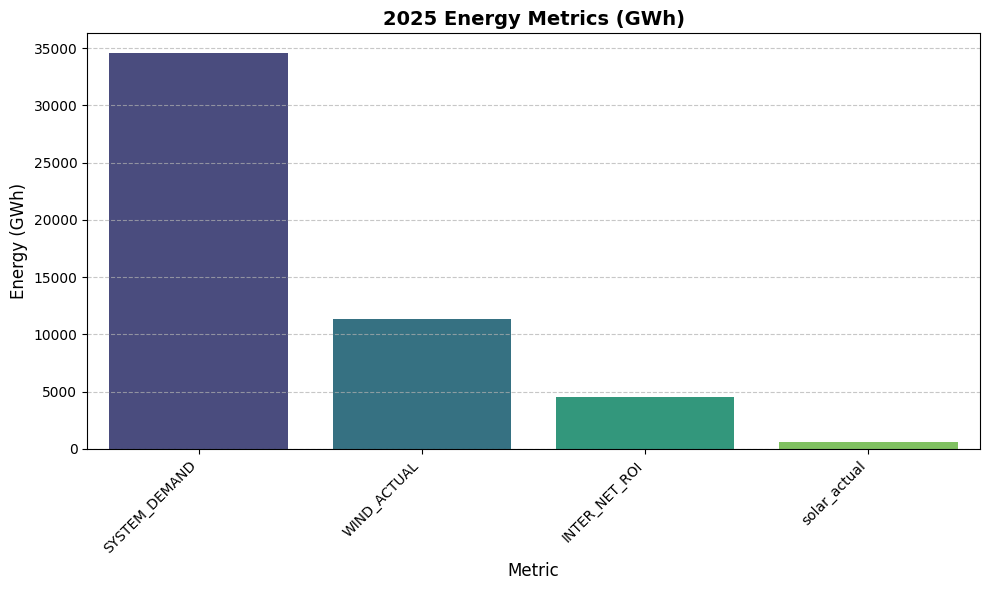

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar chart for yearly_sums_gwh
plt.figure(figsize=(10, 6))
sns.barplot(x=yearly_sums_gwh.index, y=yearly_sums_gwh.values, palette='viridis', hue=yearly_sums_gwh.index, legend=False)

plt.title('2025 Energy Metrics (GWh)', fontsize=14, fontweight='bold')
plt.xlabel('Metric', fontsize=12)
plt.ylabel('Energy (GWh)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

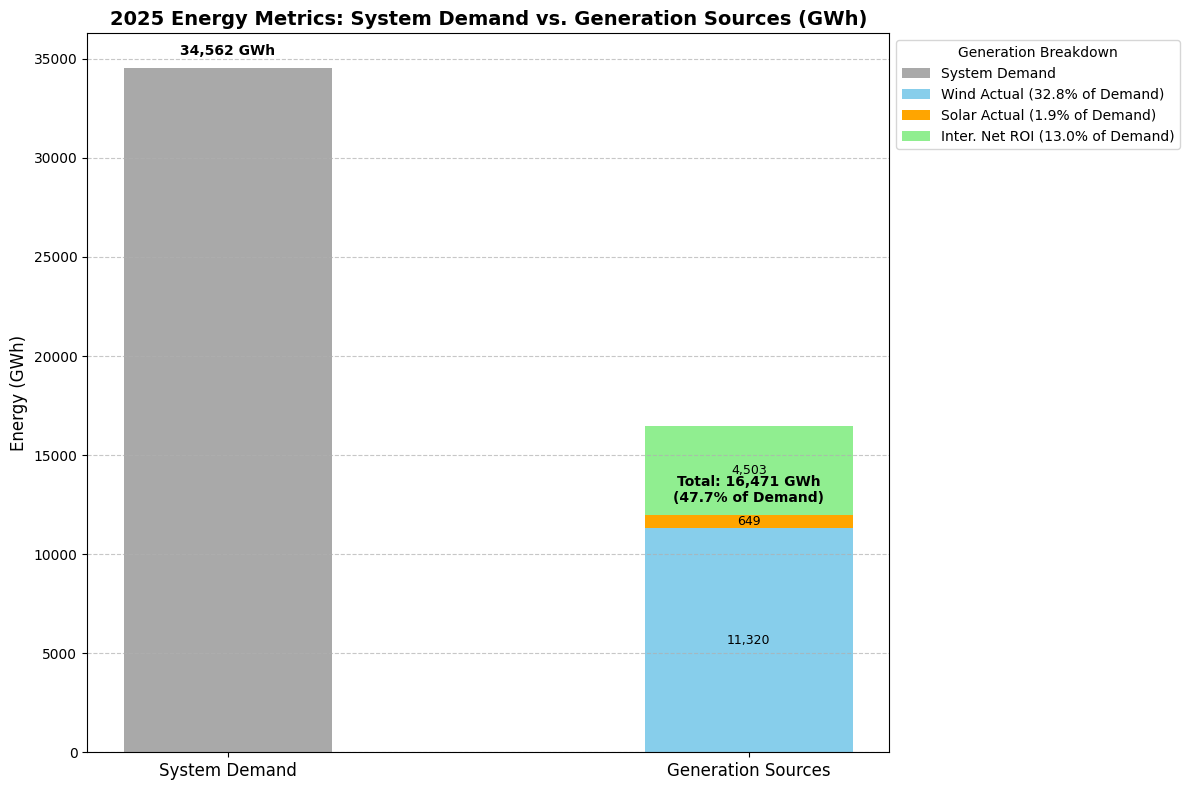

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data in GWh from yearly_sums_gwh
system_demand_gwh = yearly_sums_gwh['SYSTEM_DEMAND']
wind_actual_gwh = yearly_sums_gwh['WIND_ACTUAL']
solar_actual_gwh = yearly_sums_gwh['solar_actual']
inter_net_roi_gwh = yearly_sums_gwh['INTER_NET_ROI']

# Calculate percentages relative to SYSTEM_DEMAND
wind_pct_of_demand = (wind_actual_gwh / system_demand_gwh) * 100
solar_pct_of_demand = (solar_actual_gwh / system_demand_gwh) * 100
inter_net_roi_pct_of_demand = (inter_net_roi_gwh / system_demand_gwh) * 100
total_gen_from_sources = wind_actual_gwh + solar_actual_gwh + inter_net_roi_gwh
total_gen_pct_of_demand = (total_gen_from_sources / system_demand_gwh) * 100

# Plotting
fig, ax = plt.subplots(figsize=(12, 8))

bar_width = 0.4
index = np.arange(2) # Two bars: System Demand and Generation Sources

# Bar for System Demand
ax.bar(index[0], system_demand_gwh, bar_width, label='System Demand', color='darkgrey')
ax.text(index[0], system_demand_gwh + 500, f'{system_demand_gwh:,.0f} GWh', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Stacked bar for Generation Sources
bottom_val = 0
bar1 = ax.bar(index[1], wind_actual_gwh, bar_width, label=f'Wind Actual ({wind_pct_of_demand:.1f}% of Demand)', color='skyblue', bottom=bottom_val)
bottom_val += wind_actual_gwh
bar2 = ax.bar(index[1], solar_actual_gwh, bar_width, label=f'Solar Actual ({solar_pct_of_demand:.1f}% of Demand)', color='orange', bottom=bottom_val)
bottom_val += solar_actual_gwh
bar3 = ax.bar(index[1], inter_net_roi_gwh, bar_width, label=f'Inter. Net ROI ({inter_net_roi_pct_of_demand:.1f}% of Demand)', color='lightgreen', bottom=bottom_val)

# Add GWh labels for stacked bars
ax.text(index[1], wind_actual_gwh / 2, f'{wind_actual_gwh:,.0f}', ha='center', va='center', color='black', fontsize=9)
ax.text(index[1], wind_actual_gwh + solar_actual_gwh / 2, f'{solar_actual_gwh:,.0f}', ha='center', va='center', color='black', fontsize=9)
ax.text(index[1], wind_actual_gwh + solar_actual_gwh + inter_net_roi_gwh / 2, f'{inter_net_roi_gwh:,.0f}', ha='center', va='center', color='black', fontsize=9)

# Add total GWh and percentage of demand for the stacked bar
ax.text(index[1], bottom_val + 500, f'Total: {total_gen_from_sources:,.0f} GWh\n({total_gen_pct_of_demand:.1f}% of Demand)', ha='center', va='bottom', fontsize=10, fontweight='bold')


ax.set_ylabel('Energy (GWh)', fontsize=12)
ax.set_title('2025 Energy Metrics: System Demand vs. Generation Sources (GWh)', fontsize=14, fontweight='bold')
ax.set_xticks(index)
ax.set_xticklabels(['System Demand', 'Generation Sources'], fontsize=12)
ax.legend(title='Generation Breakdown', loc='upper left', bbox_to_anchor=(1, 1))
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

This chart clearly illustrates the total System Demand for 2025 and how the various generation sources (Wind, Solar, and Net Interconnection Imports) contribute to meeting that demand. The percentages give a direct comparison of each source's contribution relative to the overall system demand.

This bar chart visually represents the total energy in Gigawatt-hours for each key metric in 2025. As you can see, System Demand is significantly higher than other categories, with Wind Actual being the next largest contributor.

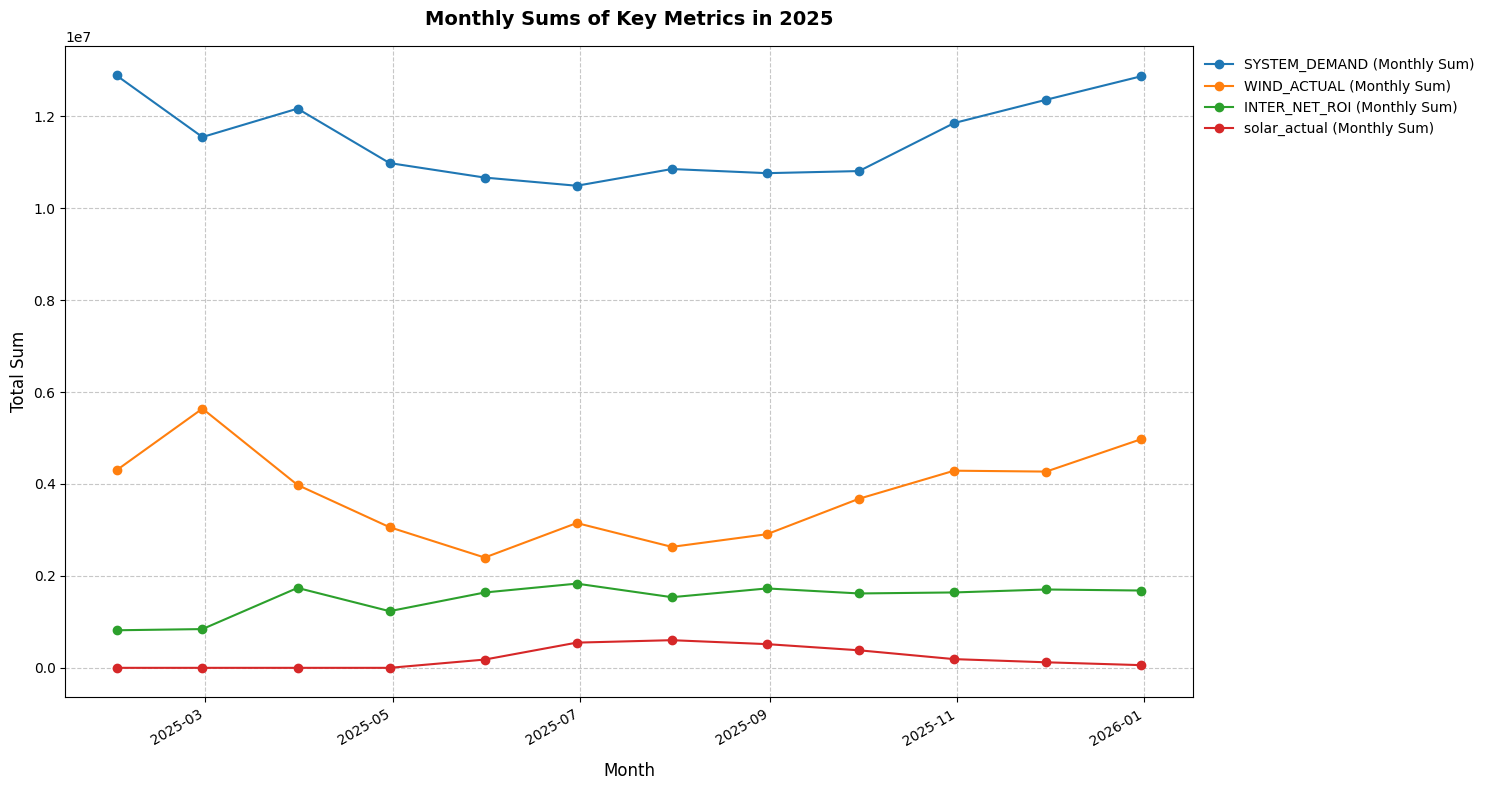

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Plotting all monthly sums on a single chart
fig, ax = plt.subplots(1, 1, figsize=(15, 8))

for column in columns_to_sum:
    ax.plot(monthly_sums.index, monthly_sums[column], marker='o', linestyle='-', label=f'{column} (Monthly Sum)')

ax.set_title('Monthly Sums of Key Metrics in 2025', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Month', fontsize=12, labelpad=10)
ax.set_ylabel('Total Sum', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=True, facecolor='white', edgecolor='none') # Place legend outside

# Format x-axis (dates)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate() # Rotates date labels for readability

plt.tight_layout()
plt.show()

### Loading and Processing 2024 Energy Data for Comparison

In [ ]:
years_to_process_2024 = [2024]
all_month_ranges_2024 = get_month_ranges(years_to_process_2024)

monthly_dataframes_2024 = []

for start_date, end_date in all_month_ranges_2024:
    # Construct the expected CSV file path for the month
    dates_str = f"{start_date.strftime('%Y-%m-%d')}_{end_date.strftime('%Y-%m-%d')}"
    output_path = f"/content/drive/My Drive/climate/energy2026_all/eirgrid_{dates_str}.csv"

    df_month = pd.DataFrame() # Initialize df_month as empty

    try:
        # Attempt to load from CSV first
        print(f"Attempting to load data for {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')} from {output_path}")
        df_month = pd.read_csv(output_path, index_col=0, parse_dates=True)
        if not df_month.empty:
            print(f"Successfully loaded data from CSV for {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}. Rows: {len(df_month)}")
        else:
            print(f"File {output_path} loaded but was empty. Will attempt to fetch from URL.")
            df_month = pd.DataFrame() # Reset df_month if empty
    except FileNotFoundError:
        print(f"File not found at {output_path}. Fetching data from URL.")
    except Exception as e:
        print(f"Error loading file {output_path}: {e}. Fetching data from URL.")
        df_month = pd.DataFrame() # Reset df_month if error occurred

    # If df_month is still empty (either file not found or empty), fetch from URL
    if df_month.empty:
        print(f"Fetching data from URL for: Start: {start_date.strftime('%Y-%m-%d')}, End: {end_date.strftime('%Y-%m-%d')}")
        fetched_df = build_eirgrid_month_frame(region= "ROI", start_date=start_date , end_date=end_date)
        if not fetched_df.empty:
            monthly_dataframes_2024.append(fetched_df)
            print(f"Successfully fetched and saved data for {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}. Rows: {len(fetched_df)}")
        else:
            print(f"No data fetched from URL for {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}.")
    elif not df_month.empty:
        monthly_dataframes_2024.append(df_month)

# Concatenate all monthly DataFrames into a single DataFrame for the full year
if monthly_dataframes_2024:
    full_year_df_2024 = pd.concat(monthly_dataframes_2024).sort_index()
    # Ensure INTER_NET_ROI is calculated for 2024 as well, handling potential NaNs
    if 'INTER_EWIC' in full_year_df_2024.columns and 'INTER_GRNLK' in full_year_df_2024.columns:
        full_year_df_2024['INTER_NET_ROI'] = full_year_df_2024['INTER_EWIC'].fillna(0) + full_year_df_2024['INTER_GRNLK'].fillna(0)
    else:
        full_year_df_2024['INTER_NET_ROI'] = 0 # Default if columns are missing

    print("\nFull year 2024 DataFrame created.")
    print(f"Total rows in full_year_df_2024: {len(full_year_df_2024)}")
    display(full_year_df_2024.head())
    display(full_year_df_2024.tail())
else:
    print("No data was loaded or fetched for 2024.")

Attempting to load data for 2024-01-01 to 2024-01-31 from /content/drive/My Drive/climate/energy2026/eirgrid_2024-01-01_2024-01-31.csv
File not found at /content/drive/My Drive/climate/energy2026/eirgrid_2024-01-01_2024-01-31.csv. Fetching data from URL.
Fetching data from URL for: Start: 2024-01-01, End: 2024-01-31
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=demandactual&region=ROI&datefrom=01-Jan-2024%2000%3A00&dateto=31-Jan-2024%2023%3A59
DataFrame for demandactual has 2976 rows.
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=windactual&region=ROI&datefrom=01-Jan-2024%2000%3A00&dateto=31-Jan-2024%2023%3A59
DataFrame for windactual has 2976 rows.
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=interconnection&region=ROI&datefrom=01-Jan-2024%2000%3A00&dateto=31-Jan-2024%2023%3A59
DataFrame for interconnection has 0 rows.
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc

,SYSTEM_DEMAND,WIND_ACTUAL,CO2_INTENSITY,solar_actual,solar_forecast
2024-01-31 22:45:00,4008.0,866.0,228.0,NaN,NaN
2024-01-31 23:00:00,3959.0,872.0,226.0,NaN,NaN
2024-01-31 23:15:00,3969.0,839.0,226.0,NaN,NaN
2024-01-31 23:30:00,3902.0,818.0,227.0,NaN,NaN
2024-01-31 23:45:00,3819.0,763.0,233.0,NaN,NaN


Saving DataFrame to  /content/drive/My Drive/climate/energy2026/eirgrid_2024-01-01_2024-01-31.csv
Successfully fetched and saved data for 2024-01-01 to 2024-01-31. Rows: 2976
Attempting to load data for 2024-02-01 to 2024-02-29 from /content/drive/My Drive/climate/energy2026/eirgrid_2024-02-01_2024-02-29.csv
File not found at /content/drive/My Drive/climate/energy2026/eirgrid_2024-02-01_2024-02-29.csv. Fetching data from URL.
Fetching data from URL for: Start: 2024-02-01, End: 2024-02-29
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=demandactual&region=ROI&datefrom=01-Feb-2024%2000%3A00&dateto=29-Feb-2024%2023%3A59
DataFrame for demandactual has 2784 rows.
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=windactual&region=ROI&datefrom=01-Feb-2024%2000%3A00&dateto=29-Feb-2024%2023%3A59
DataFrame for windactual has 2784 rows.
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=interconnection&region

,SYSTEM_DEMAND,WIND_ACTUAL,CO2_INTENSITY,solar_actual,solar_forecast
2024-02-29 22:45:00,4029.0,1336.0,186.0,NaN,NaN
2024-02-29 23:00:00,3995.0,1467.0,177.0,NaN,NaN
2024-02-29 23:15:00,4035.0,1654.0,167.0,NaN,NaN
2024-02-29 23:30:00,3968.0,1738.0,167.0,NaN,NaN
2024-02-29 23:45:00,3894.0,1587.0,173.0,NaN,NaN


Saving DataFrame to  /content/drive/My Drive/climate/energy2026/eirgrid_2024-02-01_2024-02-29.csv
Successfully fetched and saved data for 2024-02-01 to 2024-02-29. Rows: 2784
Attempting to load data for 2024-03-01 to 2024-03-31 from /content/drive/My Drive/climate/energy2026/eirgrid_2024-03-01_2024-03-31.csv
File not found at /content/drive/My Drive/climate/energy2026/eirgrid_2024-03-01_2024-03-31.csv. Fetching data from URL.
Fetching data from URL for: Start: 2024-03-01, End: 2024-03-31
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=demandactual&region=ROI&datefrom=01-Mar-2024%2000%3A00&dateto=31-Mar-2024%2023%3A59
DataFrame for demandactual has 2972 rows.
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=windactual&region=ROI&datefrom=01-Mar-2024%2000%3A00&dateto=31-Mar-2024%2023%3A59
DataFrame for windactual has 2972 rows.
Calling URL: https://www.smartgriddashboard.com/DashboardService.svc/data?area=interconnection&region

,SYSTEM_DEMAND,WIND_ACTUAL,CO2_INTENSITY,solar_actual,solar_forecast
2024-03-31 22:45:00,3424.0,1449.0,185.0,NaN,NaN
2024-03-31 23:00:00,3379.0,1473.0,175.0,NaN,NaN
2024-03-31 23:15:00,3333.0,1481.0,181.0,NaN,NaN
2024-03-31 23:30:00,3279.0,1480.0,183.0,NaN,NaN
2024-03-31 23:45:00,3235.0,1467.0,183.0,NaN,NaN


... (17 outputs left out)

,SYSTEM_DEMAND,WIND_ACTUAL,INTER_EWIC,INTER_GRNLK,INTER_NET_ROI,CO2_INTENSITY,solar_actual,solar_forecast
2024-12-31 22:45:00,3577.0,1828.0,530.0,0.0,530.0,104.0,NaN,NaN
2024-12-31 23:00:00,3555.0,1794.0,530.0,0.0,530.0,104.0,NaN,NaN
2024-12-31 23:15:00,3645.0,1960.0,456.0,0.0,456.0,102.0,NaN,NaN
2024-12-31 23:30:00,3612.0,1942.0,416.0,0.0,416.0,103.0,NaN,NaN
2024-12-31 23:45:00,3579.0,1861.0,473.0,0.0,473.0,104.0,NaN,NaN


Saving DataFrame to  /content/drive/My Drive/climate/energy2026/eirgrid_2024-12-01_2024-12-31.csv
Successfully fetched and saved data for 2024-12-01 to 2024-12-31. Rows: 2976

Full year 2024 DataFrame created.
Total rows in full_year_df_2024: 35132


,SYSTEM_DEMAND,WIND_ACTUAL,CO2_INTENSITY,solar_actual,solar_forecast,INTER_EWIC,INTER_NET_ROI,INTER_GRNLK
2024-01-01 00:00:00,3460.0,2263.0,120.0,NaN,NaN,NaN,0.0,NaN
2024-01-01 00:15:00,3455.0,2181.0,129.0,NaN,NaN,NaN,0.0,NaN
2024-01-01 00:30:00,3416.0,2228.0,131.0,NaN,NaN,NaN,0.0,NaN
2024-01-01 00:45:00,3373.0,2186.0,136.0,NaN,NaN,NaN,0.0,NaN
2024-01-01 01:00:00,3334.0,2128.0,134.0,NaN,NaN,NaN,0.0,NaN


,SYSTEM_DEMAND,WIND_ACTUAL,CO2_INTENSITY,solar_actual,solar_forecast,INTER_EWIC,INTER_NET_ROI,INTER_GRNLK
2024-12-31 22:45:00,3577.0,1828.0,104.0,NaN,NaN,530.0,530.0,0.0
2024-12-31 23:00:00,3555.0,1794.0,104.0,NaN,NaN,530.0,530.0,0.0
2024-12-31 23:15:00,3645.0,1960.0,102.0,NaN,NaN,456.0,456.0,0.0
2024-12-31 23:30:00,3612.0,1942.0,103.0,NaN,NaN,416.0,416.0,0.0
2024-12-31 23:45:00,3579.0,1861.0,104.0,NaN,NaN,473.0,473.0,0.0


### Yearly Sums for Key Metrics (2024)

In [ ]:
columns_to_sum_2024 = ['SYSTEM_DEMAND', 'WIND_ACTUAL', 'INTER_NET_ROI', 'solar_actual']

# Calculate yearly sums for 2024
yearly_sums_2024 = full_year_df_2024[columns_to_sum_2024].sum()
print("\nYearly Sums for 2024:")
display(yearly_sums_2024)

# Convert yearly sums to GWh for 2024
yearly_sums_gwh_2024 = yearly_sums_2024 * (15 / 60) / 1000

print("\nYearly Sums for 2024 (in GWh):")
display(yearly_sums_gwh_2024)


Yearly Sums for 2024:


,0
SYSTEM_DEMAND,134791610.0
WIND_ACTUAL,44499637.0
INTER_NET_ROI,7862163.0
solar_actual,0.0



Yearly Sums for 2024 (in GWh):


,0
SYSTEM_DEMAND,33697.90250
WIND_ACTUAL,11124.90925
INTER_NET_ROI,1965.54075
solar_actual,0.00000


### Comparing 2024 and 2025 Energy Metrics


Yearly Energy Metrics Comparison (GWh):


,2024,2025
SYSTEM_DEMAND,33697.90250,34561.56000
WIND_ACTUAL,11124.90925,11319.58400
INTER_NET_ROI,1965.54075,4502.95625
solar_actual,0.00000,648.76300


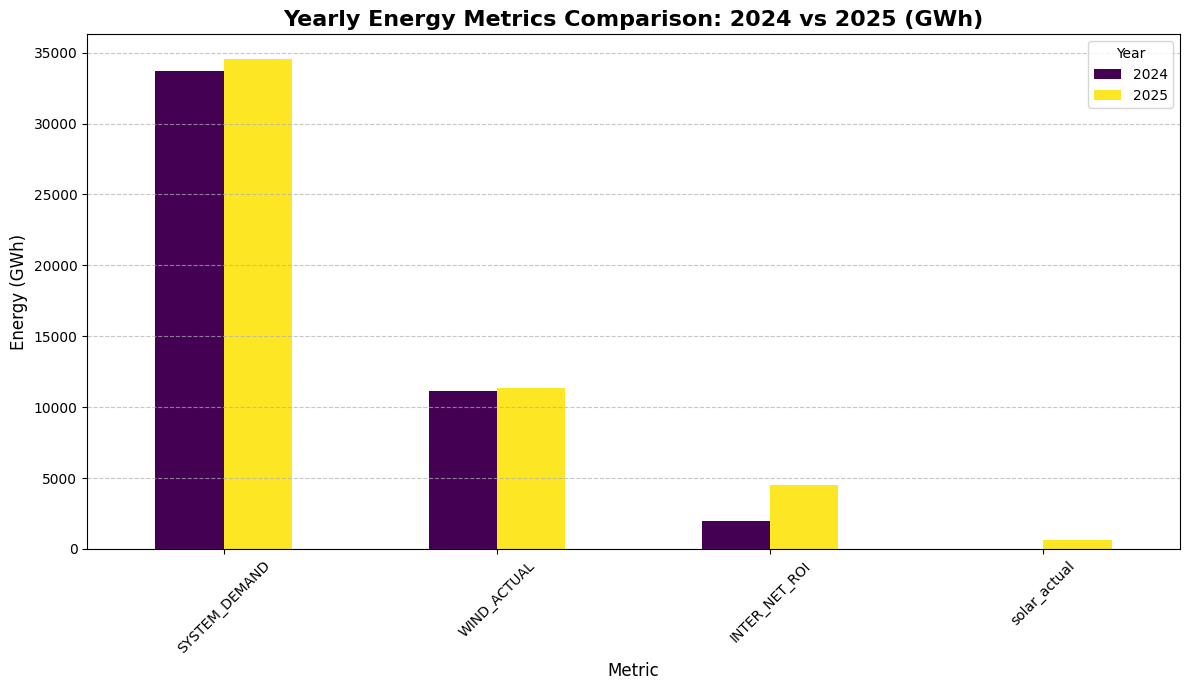

In [ ]:
# Combine yearly sums for comparison
comparison_df = pd.DataFrame({
    '2024': yearly_sums_gwh_2024,
    '2025': yearly_sums_gwh
})

print("\nYearly Energy Metrics Comparison (GWh):")
display(comparison_df)

# Plotting the comparison
fig, ax = plt.subplots(figsize=(12, 7))
comparison_df.plot(kind='bar', ax=ax, colormap='viridis')

ax.set_title('Yearly Energy Metrics Comparison: 2024 vs 2025 (GWh)', fontsize=16, fontweight='bold')
ax.set_xlabel('Metric', fontsize=12)
ax.set_ylabel('Energy (GWh)', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(title='Year')
plt.tight_layout()
plt.show()

### Stacked Bar Chart: Percentage Contribution of Renewables (2024 vs 2025)

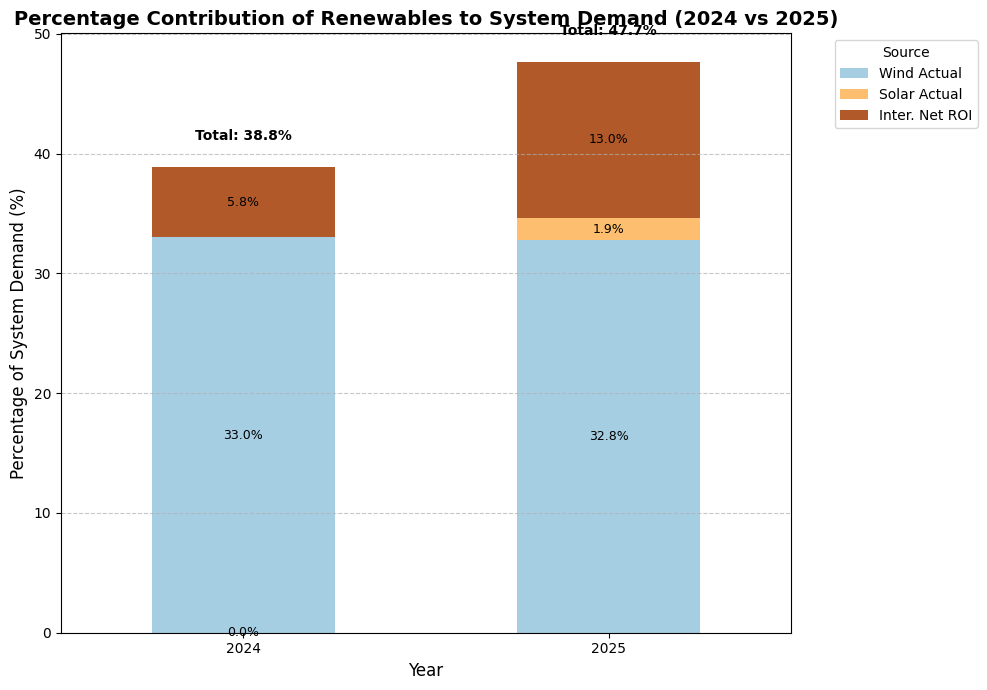

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data for 2024
system_demand_2024 = yearly_sums_gwh_2024['SYSTEM_DEMAND']
wind_actual_2024 = yearly_sums_gwh_2024['WIND_ACTUAL']
solar_actual_2024 = yearly_sums_gwh_2024['solar_actual']
inter_net_roi_2024 = yearly_sums_gwh_2024['INTER_NET_ROI']

# Prepare data for 2025
system_demand_2025 = yearly_sums_gwh['SYSTEM_DEMAND']
wind_actual_2025 = yearly_sums_gwh['WIND_ACTUAL']
solar_actual_2025 = yearly_sums_gwh['solar_actual']
inter_net_roi_2025 = yearly_sums_gwh['INTER_NET_ROI']

# Calculate percentage contributions for 2024
wind_pct_2024 = (wind_actual_2024 / system_demand_2024) * 100 if system_demand_2024 > 0 else 0
solar_pct_2024 = (solar_actual_2024 / system_demand_2024) * 100 if system_demand_2024 > 0 else 0
inter_net_roi_pct_2024 = (inter_net_roi_2024 / system_demand_2024) * 100 if system_demand_2024 > 0 else 0

# Calculate percentage contributions for 2025
wind_pct_2025 = (wind_actual_2025 / system_demand_2025) * 100 if system_demand_2025 > 0 else 0
solar_pct_2025 = (solar_actual_2025 / system_demand_2025) * 100 if system_demand_2025 > 0 else 0
inter_net_roi_pct_2025 = (inter_net_roi_2025 / system_demand_2025) * 100 if system_demand_2025 > 0 else 0

# Create a DataFrame for plotting percentages
plot_data = pd.DataFrame({
    'Wind Actual': [wind_pct_2024, wind_pct_2025],
    'Solar Actual': [solar_pct_2024, solar_pct_2025],
    'Inter. Net ROI': [inter_net_roi_pct_2024, inter_net_roi_pct_2025]
}, index=['2024', '2025'])

# Plotting
fig, ax = plt.subplots(figsize=(10, 7))

plot_data.plot(kind='bar', stacked=True, ax=ax, colormap='Paired')

ax.set_title('Percentage Contribution of Renewables to System Demand (2024 vs 2025)', fontsize=14, fontweight='bold')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Percentage of System Demand (%)', fontsize=12)
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(title='Source', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add total percentage labels on top of each bar
for container in ax.containers:
    labels = [f'{w:.1f}%' for w in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=9)

# Calculate total renewable percentage for each year
total_renewable_pct_2024 = wind_pct_2024 + solar_pct_2024 + inter_net_roi_pct_2024
total_renewable_pct_2025 = wind_pct_2025 + solar_pct_2025 + inter_net_roi_pct_2025

ax.text(0, total_renewable_pct_2024 + 2, f'Total: {total_renewable_pct_2024:.1f}%', ha='center', va='bottom', fontweight='bold')
ax.text(1, total_renewable_pct_2025 + 2, f'Total: {total_renewable_pct_2025:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()